<div style="text-align:center; line-height:1.6">

МИНИСТЕРСТВО НАУКИ И ВЫСШЕГО ОБРАЗОВАНИЯ РОССИЙСКОЙ ФЕДЕРАЦИИ<br>
Новосибирский государственный технический университет<br>
Факультет автоматики и вычислительной техники

# ОТЧЁТ
## по лабораторной работе № 3
### «Кластеризация»

Дисциплина «Методы анализа данных» · Датасет: **Wine Dataset** (UCI / Kaggle)

</div>

<div style="text-align:right">
Выполнил: студент гр. АВТ-313 Савченко В.Э.<br>
Проверила: Ганелина Н.Д.
</div>

<div style="text-align:center">Новосибирск, 2026</div>

---

## Содержание

1. Введение
2. Описание датасета
3. Предобработка данных
4. Ход работы (4.1 Визуальная оценка структуры и выбор методов · 4.2 Подбор числа кластеров ·
   4.3 Построение моделей · 4.4 Метрики качества · 4.5 Влияние параметров и устойчивость)
5. Визуализация и интерпретация кластеров
6. Заключение
7. Список источников
8. Приложение. Листинг программного кода

# 1. Введение

**Цель работы** — изучение алгоритмов кластеризации, приобретение навыков оценки качества разбиения
данных на кластеры и интерпретации результатов.

**Задачи:**

1. Провести дескриптивный анализ датасета: размерность, типы, пропуски, распределения, выбросы,
   информационная значимость признаков; проверить условия применимости кластеризации.
2. Обосновать и выполнить масштабирование признаков.
3. По матрице диаграмм рассеивания и проекции на главные компоненты оценить кластерную структуру
   и выбрать два метода кластеризации.
4. Подобрать число кластеров методом локтя, силуэтным анализом и по дендрограмме.
5. Выполнить кластеризацию методами **K-means** и **иерархической агломеративной кластеризации
   (метод Уорда)**.
6. Рассчитать внутренние метрики (силуэт, Калински — Харабаш, Дэвис — Боулдин, внутри- и межкластерные
   расстояния, компактность, центры) и внешние (Rand, ARI, Жаккар, NMI) — истинные сорта известны.
7. Исследовать влияние параметров (k, init, n_init для K-means; способ объединения для иерархической;
   eps и min_samples для DBSCAN) и устойчивость кластеров.
8. Визуализировать кластеры в пространстве PCA, интерпретировать их в исходных единицах и сравнить методы.

**Внутренние метрики** (не используют истинные классы):

| Метрика | Формула | Как читать |
|---|---|---|
| Силуэт | s(i) = (b(i) − a(i)) / max(a(i), b(i)); a — среднее расстояние до своего кластера, b — до ближайшего чужого | от −1 до 1; > 0,5 — чёткая структура, 0,25–0,5 — слабая, но реальная, < 0,25 — размытая |
| Калински — Харабаш | (межкластерный разброс / (k − 1)) / (внутрикластерный / (n − k)) | чем больше, тем лучше; сравнивается только между вариантами одних данных |
| Дэвис — Боулдин | среднее по кластерам max_j (Sᵢ + Sⱼ) / d(cᵢ, cⱼ) | ≥ 0; чем меньше, тем лучше |
| Инерция (SSE) | Σ ‖xᵢ − c(xᵢ)‖² | основа метода локтя; всегда падает с ростом k |

**Внешние метрики** (сравнение с истинными классами): индекс Rand и скорректированный ARI (0 — случайное
совпадение, 1 — полное), индекс Жаккара по парам объектов, нормированная взаимная информация (NMI).

In [1]:
# Импорт библиотек
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist, cdist

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import (silhouette_score, silhouette_samples, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score, rand_score,
                             normalized_mutual_info_score, homogeneity_score,
                             completeness_score, v_measure_score, fowlkes_mallows_score)
from sklearn.metrics.cluster import contingency_matrix, pair_confusion_matrix

warnings.filterwarnings("ignore")
SEED = 42                                   # фиксируем случайность (инициализация K-means, Хопкинс)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.family"] = "DejaVu Sans"
pd.set_option("display.width", 150)

# 2. Описание датасета

**Wine Dataset** (UCI Machine Learning Repository; размещён также на Kaggle) — результаты химического
анализа **178 вин**, полученных из **трёх сортов винограда** одного региона Италии. Для каждого вина
измерены **13 непрерывных химических показателей**. Сорт известен, но в кластеризации **не используется**:
задача — проверить, восстановят ли алгоритмы группы вин без подсказки, только по химии.

| Признак | Смысл |
|---|---|
| `alcohol` | содержание алкоголя, % |
| `malic_acid` | яблочная кислота, г/л |
| `ash`, `alcalinity_of_ash` | зола и её щёлочность |
| `magnesium` | магний, мг/л |
| `total_phenols`, `flavanoids`, `nonflavanoid_phenols` | фенольные соединения (в т. ч. флавоноиды) |
| `proanthocyanins` | проантоцианидины |
| `color_intensity`, `hue` | интенсивность и оттенок цвета |
| `od280/od315_of_diluted_wines` | оптическая плотность разбавленного вина (содержание белков) |
| `proline` | аминокислота пролин, мг/л |

In [2]:
# Wine Dataset (UCI / Kaggle): химический анализ 178 вин трёх сортов винограда из одного региона Италии
wine = load_wine(as_frame=True)
df = wine.frame.copy()                      # 13 признаков + столбец target
print("Размер:", df.shape, "-> объектов", df.shape[0], ", признаков", df.shape[1] - 1)
print("Типы:", df.dtypes.astype(str).value_counts().to_dict())
df.head()

Размер: (178, 14) -> объектов 178 , признаков 13
Типы: {'float64': 13, 'int64': 1}


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [3]:
# Метки сортов отделяются СРАЗУ: в кластеризации они не участвуют,
# используются только в конце для внешних метрик (сравнение кластеров с реальными сортами)
y_true = df.pop("target").values
FEATURES = list(df.columns)
X = df[FEATURES]
print("Признаки для кластеризации (", len(FEATURES), "):", FEATURES)
print("Истинные классы (только для проверки):", dict(zip(*np.unique(y_true, return_counts=True))))
print("target в X:", "target" in X.columns)

Признаки для кластеризации ( 13 ): ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Истинные классы (только для проверки): {np.int64(0): np.int64(59), np.int64(1): np.int64(71), np.int64(2): np.int64(48)}
target в X: False


Датасет содержит 178 объектов и 13 признаков, все типа `float64`. Метки сортов (`target`) сразу
вынесены в отдельный массив `y_true` и удалены из таблицы признаков — они **не попадают** в масштабирование
и кластеризацию, а используются только в разделе 4.4 для внешних метрик. Сорта: 59, 71 и 48 вин —
классы умеренно несбалансированы.

In [4]:
print("Пропусков всего:", X.isna().sum().sum())
print("Дубликатов строк:", X.duplicated().sum())
print("Бесконечных значений:", np.isinf(X.values).sum())

Пропусков всего: 0
Дубликатов строк: 0
Бесконечных значений: 0


Пропусков, дубликатов и бесконечных значений нет — обработка пропусков не требуется.

In [5]:
desc = X.describe().T
desc["CV"] = desc["std"] / desc["mean"]          # коэффициент вариации — относительный разброс
desc["skew"] = X.skew()                          # асимметрия
desc["kurt"] = X.kurtosis()                      # избыточный эксцесс
desc["normaltest p"] = [stats.normaltest(X[c]).pvalue for c in FEATURES]   # H0: распределение нормально
desc.round(3)

,count,mean,std,min,25%,50%,75%,max,CV,skew,kurt,normaltest p
alcohol,178.0,13.001,0.812,11.03,12.362,13.050,13.678,14.83,0.062,-0.051,-0.852,0.000
malic_acid,178.0,2.336,1.117,0.74,1.602,1.865,3.082,5.80,0.478,1.040,0.299,0.000
ash,178.0,2.367,0.274,1.36,2.210,2.360,2.558,3.23,0.116,-0.177,1.144,0.036
alcalinity_of_ash,178.0,19.495,3.340,10.60,17.200,19.500,21.500,30.00,0.171,0.213,0.488,0.210
magnesium,178.0,99.742,14.282,70.00,88.000,98.000,107.000,162.00,0.143,1.098,2.105,0.000
total_phenols,178.0,2.295,0.626,0.98,1.742,2.355,2.800,3.88,0.273,0.087,-0.836,0.001
flavanoids,178.0,2.029,0.999,0.34,1.205,2.135,2.875,5.08,0.492,0.025,-0.880,0.000
nonflavanoid_phenols,178.0,0.362,0.124,0.13,0.270,0.340,0.438,0.66,0.344,0.450,-0.637,0.003
proanthocyanins,178.0,1.591,0.572,0.41,1.250,1.555,1.950,3.58,0.360,0.517,0.555,0.008
color_intensity,178.0,5.058,2.318,1.28,3.220,4.690,6.200,13.00,0.458,0.869,0.382,0.000


**Что видно из статистик.**

- **Масштабы признаков различаются на три порядка:** пролин — от 278 до 1 680, магний — около 100,
  оттенок — около 1, нефлавоноидные фенолы — около 0,36. Без масштабирования евклидово расстояние
  определялось бы почти только пролином.
- **Разброс (CV):** у большинства признаков CV 0,24–0,49 — признаки достаточно изменчивы, чтобы различать
  объекты. Самый малый — у алкоголя (0,06), но в абсолютных единицах это 11–14,8 % — содержательная
  разница.
- **Форма распределений:** почти симметричны (|skew| ≤ 0,3) алкоголь, зола, фенолы, флавоноиды, оттенок,
  OD280; умеренно скошены вправо яблочная кислота (1,04), магний (1,10, эксцесс 2,1), интенсивность
  цвета (0,87) и пролин (0,77).
- **Тест Д'Агостино** (`normaltest`) отвергает нормальность у 11 из 13 признаков (p < 0,05);
  нормальными можно считать только щёлочность золы (p = 0,21) и оттенок (p = 0,60). Для кластеризации
  нормальность не обязательна, но она важна для понимания формы кластеров.

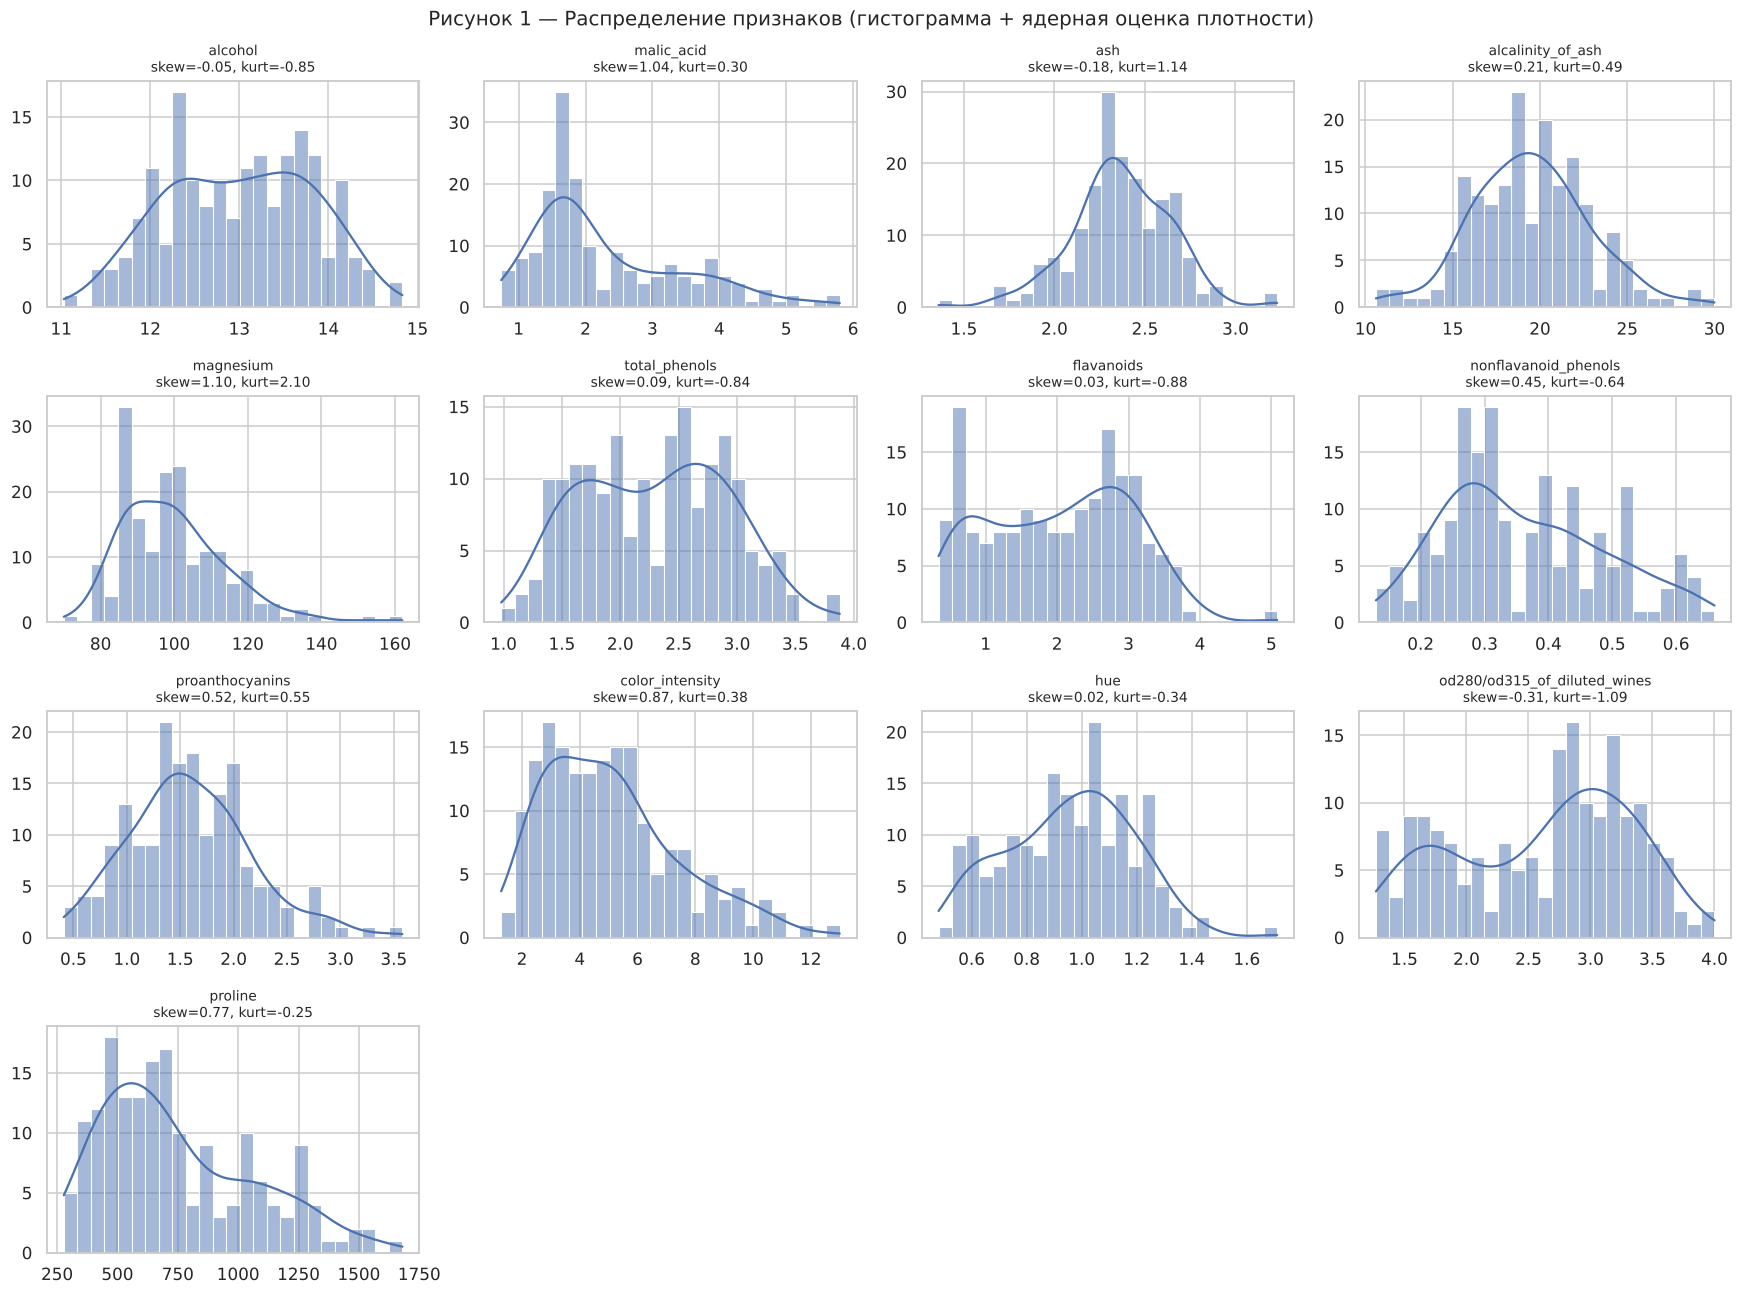

In [6]:
fig, axes = plt.subplots(4, 4, figsize=(16, 12))
for ax, c in zip(axes.ravel(), FEATURES):
    sns.histplot(X[c], bins=25, kde=True, ax=ax, color="#4C72B0")
    ax.set_title(f"{c}\nskew={X[c].skew():.2f}, kurt={X[c].kurtosis():.2f}", fontsize=9)
    ax.set_xlabel(""); ax.set_ylabel("")
for ax in axes.ravel()[len(FEATURES):]:
    ax.axis("off")
fig.suptitle("Рисунок 1 — Распределение признаков (гистограмма + ядерная оценка плотности)", fontsize=13)
fig.tight_layout(); plt.show()

**Комментарий к рисунку 1.** Главное, что дают гистограммы для кластеризации, — **многовершинность**.
У `alcohol`, `total_phenols`, `flavanoids`, `od280/od315` видны два «горба» (у флавоноидов — пик около 0,7
и второй около 2,8; у OD280 — около 1,7 и 3,0): это смесь распределений нескольких групп, то есть
признак кластерной структуры. Скошенные вправо `malic_acid`, `magnesium`, `color_intensity`, `proline`
имеют длинный хвост — там находятся выбросы (раздел ниже).

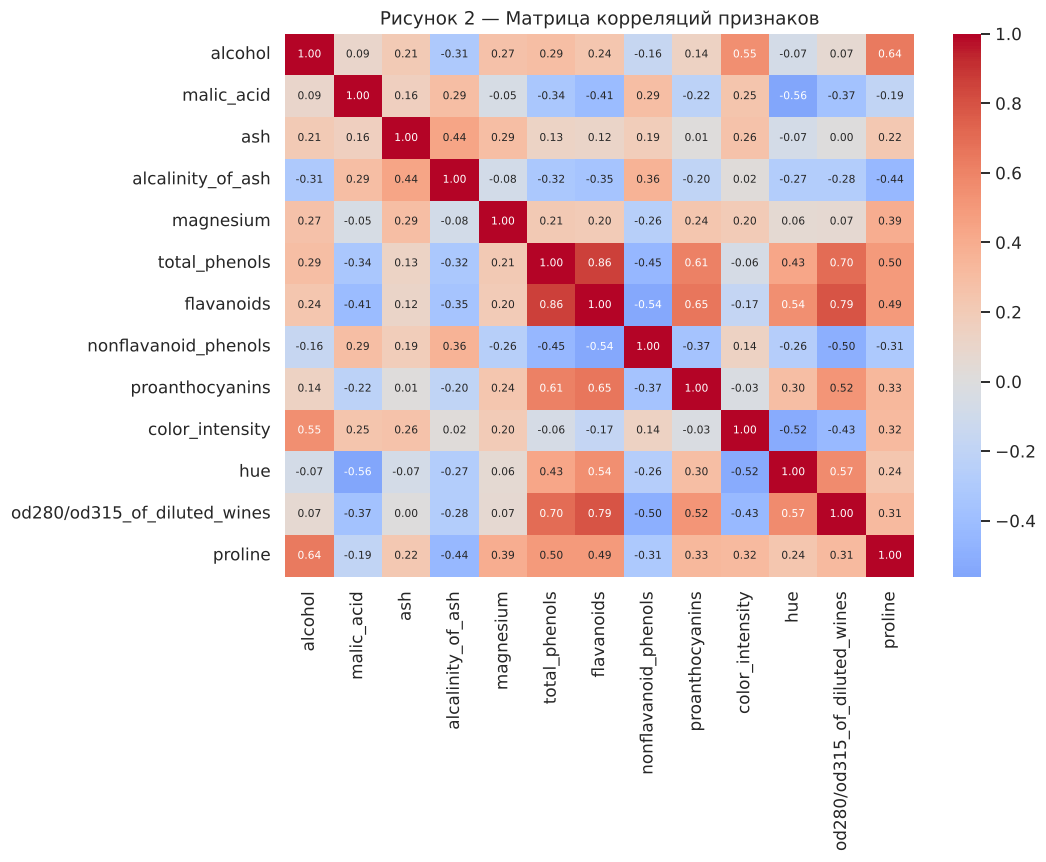

,CV,max |r| с другим,вклад в PC1-PC2,F ANOVA (справочно)
color_intensity,0.458,0.546,0.537,120.664
alcohol,0.062,0.644,0.505,135.078
proline,0.422,0.644,0.464,207.920
flavanoids,0.492,0.865,0.423,233.926
od280/od315_of_diluted_wines,0.272,0.787,0.411,189.972
hue,0.239,0.565,0.407,101.317
total_phenols,0.273,0.865,0.400,93.733
malic_acid,0.478,0.561,0.333,36.943
magnesium,0.143,0.393,0.332,12.430
ash,0.116,0.443,0.316,13.313


In [7]:
# Информационная значимость признаков для кластеризации (без использования меток):
# 1) разброс (CV): признак-константа не может разделить объекты;
# 2) корреляционная избыточность: признаки с |r| > 0.8 дублируют друг друга;
# 3) вклад в главные компоненты: признаки с большими нагрузками на PC1-PC2 формируют структуру данных
corr = X.corr()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7}, ax=ax)
ax.set_title("Рисунок 2 — Матрица корреляций признаков"); fig.tight_layout(); plt.show()

pca_tmp = PCA().fit(StandardScaler().fit_transform(X))
load2 = pd.DataFrame(pca_tmp.components_[:2].T, index=FEATURES, columns=["PC1", "PC2"])
info = pd.DataFrame({"CV": desc["CV"],
                     "max |r| с другим": (corr.abs() - np.eye(len(corr))).max(),
                     "вклад в PC1-PC2": np.sqrt((load2 ** 2).sum(1))})
# Справочно (метки в кластеризации НЕ используются): F-статистика ANOVA различий между сортами
info["F ANOVA (справочно)"] = [stats.f_oneway(*[X[c][y_true == k] for k in range(3)]).statistic for c in FEATURES]
info.sort_values("вклад в PC1-PC2", ascending=False).round(3)

**Информационная значимость признаков** оценивалась без использования меток тремя способами:

- **Разброс (CV)** — ни один признак не близок к константе, исключать нечего.
- **Корреляционная избыточность** — сильные связи: `total_phenols` ↔ `flavanoids` (r = 0,86),
  `flavanoids` ↔ `od280/od315` (0,79). Это одна «фенольная» группа; признаки оставлены, так как
  каждый несёт и собственную информацию (r < 0,9), а избыточность учтена при интерпретации.
- **Вклад в первые две главные компоненты** — сильнее всего формируют структуру данных
  `color_intensity`, `alcohol`, `proline`, `flavanoids`, `od280/od315` и `hue`; слабее всего —
  `alcalinity_of_ash`, `nonflavanoid_phenols`, `ash`.

Справочная F-статистика ANOVA (с метками — только для проверки, в кластеризации не участвует)
подтверждает: самые разделяющие признаки — флавоноиды (F = 234), пролин (208), OD280 (190), алкоголь
(135), интенсивность цвета (121); самые слабые — магний (12) и зола (13). **Решение: все 13 признаков
сохранены** — слабых мало, а их удаление существенно не изменит евклидовы расстояния.

In [8]:
# Проверка осмысленности кластеризации — статистика Хопкинса H:
# H ≈ 0.5 — данные распределены случайно (кластеров нет), H -> 1 — выраженная кластерная структура
def hopkins(Xa, frac=0.1, seed=SEED):
    rng = np.random.default_rng(seed)
    n, d = Xa.shape
    m = max(1, int(frac * n))
    nn = NearestNeighbors(n_neighbors=2).fit(Xa)
    idx = rng.choice(n, m, replace=False)
    w = nn.kneighbors(Xa[idx], 2)[0][:, 1]                     # расстояние от реальных точек до ближайшего соседа
    U = rng.uniform(Xa.min(0), Xa.max(0), (m, d))             # равномерно случайные точки в том же объёме
    u = nn.kneighbors(U, 1)[0][:, 0]                           # расстояние от случайных точек до данных
    return u.sum() / (u.sum() + w.sum())

H = [hopkins(StandardScaler().fit_transform(X), seed=s) for s in range(30)]
print(f"Статистика Хопкинса (30 повторов): {np.mean(H):.3f} ± {np.std(H):.3f}")

Статистика Хопкинса (30 повторов): 0.711 ± 0.019


**Проверка условий применения кластеризации.**

1. **Осмысленность:** статистика Хопкинса H = 0,71 ± 0,02. При случайных данных H ≈ 0,5; значение 0,71
   означает, что реальные точки расположены друг к другу заметно ближе, чем случайные, — **кластерная
   тенденция есть** (порог «выраженной» тенденции — 0,7–0,75). Многовершинные гистограммы подтверждают это.
2. **Отсутствие классов:** классы в данных есть, но алгоритму они не передаются — моделируется ситуация
   обучения без учителя, а метки служат только для проверки результата.
3. **Выбросы** — проверены ниже.

Выбросы по IQR, по признакам: {'malic_acid': 3, 'ash': 3, 'alcalinity_of_ash': 4, 'magnesium': 4, 'proanthocyanins': 2, 'color_intensity': 4, 'hue': 1}
Объектов хотя бы с одним IQR-выбросом: 17 из 178
Объектов с |z| > 3 хотя бы по одному признаку: 10


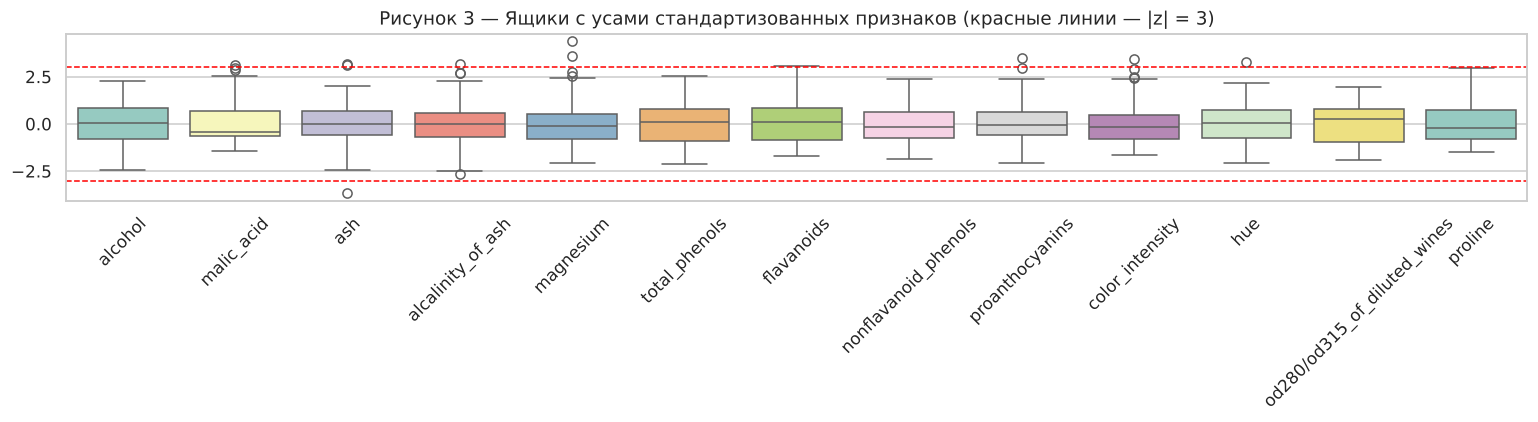

In [9]:
q1, q3 = X.quantile(0.25), X.quantile(0.75)
iqr = q3 - q1
out_iqr = (X < q1 - 1.5 * iqr) | (X > q3 + 1.5 * iqr)        # правило Тьюки (ящик с усами)
z = np.abs(stats.zscore(X))
out_z = z > 3                                                 # правило трёх сигм
print("Выбросы по IQR, по признакам:", {c: int(v) for c, v in out_iqr.sum().items() if v > 0})
print("Объектов хотя бы с одним IQR-выбросом:", int(out_iqr.any(axis=1).sum()), "из", len(X))
print("Объектов с |z| > 3 хотя бы по одному признаку:", int(out_z.any(axis=1).sum()))
fig, ax = plt.subplots(figsize=(14, 4))
sns.boxplot(data=pd.DataFrame(StandardScaler().fit_transform(X), columns=FEATURES), ax=ax, palette="Set3")
ax.axhline(3, ls="--", color="red", lw=1); ax.axhline(-3, ls="--", color="red", lw=1)
ax.set_title("Рисунок 3 — Ящики с усами стандартизованных признаков (красные линии — |z| = 3)")
ax.tick_params(axis="x", rotation=45); fig.tight_layout(); plt.show()

# Решение: выбросы НЕ удаляются (см. комментарий ниже) — просто фиксируем их число
outlier_rows = out_z.any(axis=1)

**Комментарий к рисунку 3 и решение по выбросам.** Правило Тьюки находит 21 выброс по отдельным признакам
у 17 объектов (9,6 %), правило трёх сигм — у 10 объектов (5,6 %), в основном в `magnesium`, `ash`,
`malic_acid`, `color_intensity`. Выбросы **не удаляются**:

- это не ошибки измерений, а реальные вина с необычным составом (магний 162 мг/л, интенсивность цвета 13),
  химически допустимые;
- превышения умеренные — почти все |z| < 4,4;
- выборка маленькая (178), удаление 10–17 объектов (6–10 %) заметно исказило бы пропорции сортов;
- K-means и метод Уорда чувствительны к выбросам, поэтому влияние проверено в разделе 4.5 бутстрэпом —
  кластеры устойчивы.

# 3. Предобработка данных

**Выбор метода масштабирования — `StandardScaler`** (z = (x − среднее) / σ):

- **Признаки в разных единицах** с масштабами от 0,1 до 1 000 — без выравнивания расстояние определяется
  признаком с наибольшим разбросом (пролином). K-means и метод Уорда используют евклидово расстояние,
  поэтому масштабирование обязательно.
- **Распределения в основном симметричны или умеренно скошены**, выбросов немного — стандартизация
  уместна. `MinMaxScaler` хуже: он сжимает всю шкалу по минимуму и максимуму, и один выброс
  (магний 162) «сплющил» бы остальные значения признака. `RobustScaler` (медиана и IQR) нужен при
  большом числе выбросов, здесь их 5–10 %.
- После стандартизации все признаки вносят **равный вклад** в расстояние, а инерция и метрики
  сравнимы между признаками.

Масштабируются все 13 признаков; метки не масштабируются (они не участвуют в кластеризации).

In [10]:
# Стандартизация: z = (x - mean) / std. Все 13 признаков числовые и участвуют в кластеризации.
scaler = StandardScaler()
Xs = scaler.fit_transform(X[FEATURES])
Xs_df = pd.DataFrame(Xs, columns=FEATURES)
print("До:     proline в диапазоне", X.proline.min(), "…", X.proline.max(), "| hue:", X.hue.min(), "…", X.hue.max())
print("После:  средние ≈", np.round(Xs.mean(0).max(), 6), "| стандартные отклонения ≈", np.round(Xs.std(0).min(), 6), "…", np.round(Xs.std(0).max(), 6))
Xs_df.describe().loc[["mean", "std", "min", "max"]].round(2)

До:     proline в диапазоне 278.0 … 1680.0 | hue: 0.48 … 1.71
После:  средние ≈ 0.0 | стандартные отклонения ≈ 1.0 … 1.0


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
mean,-0.00,-0.00,-0.00,-0.00,-0.00,0.00,-0.00,0.00,-0.00,0.00,0.00,0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.43,-1.43,-3.68,-2.67,-2.09,-2.11,-1.70,-1.87,-2.07,-1.63,-2.09,-1.90,-1.49
max,2.26,3.11,3.16,3.15,4.37,2.54,3.06,2.40,3.49,3.44,3.30,1.96,2.97


Проверка: после преобразования среднее каждого признака = 0, стандартное отклонение = 1. Пролин
и оттенок теперь в одной шкале (≈ −2…+3,5). Максимальные значения 3–4,4 — это те самые выбросы.

# 4. Ход работы

## 4.1. Визуальная оценка кластерной структуры и выбор методов

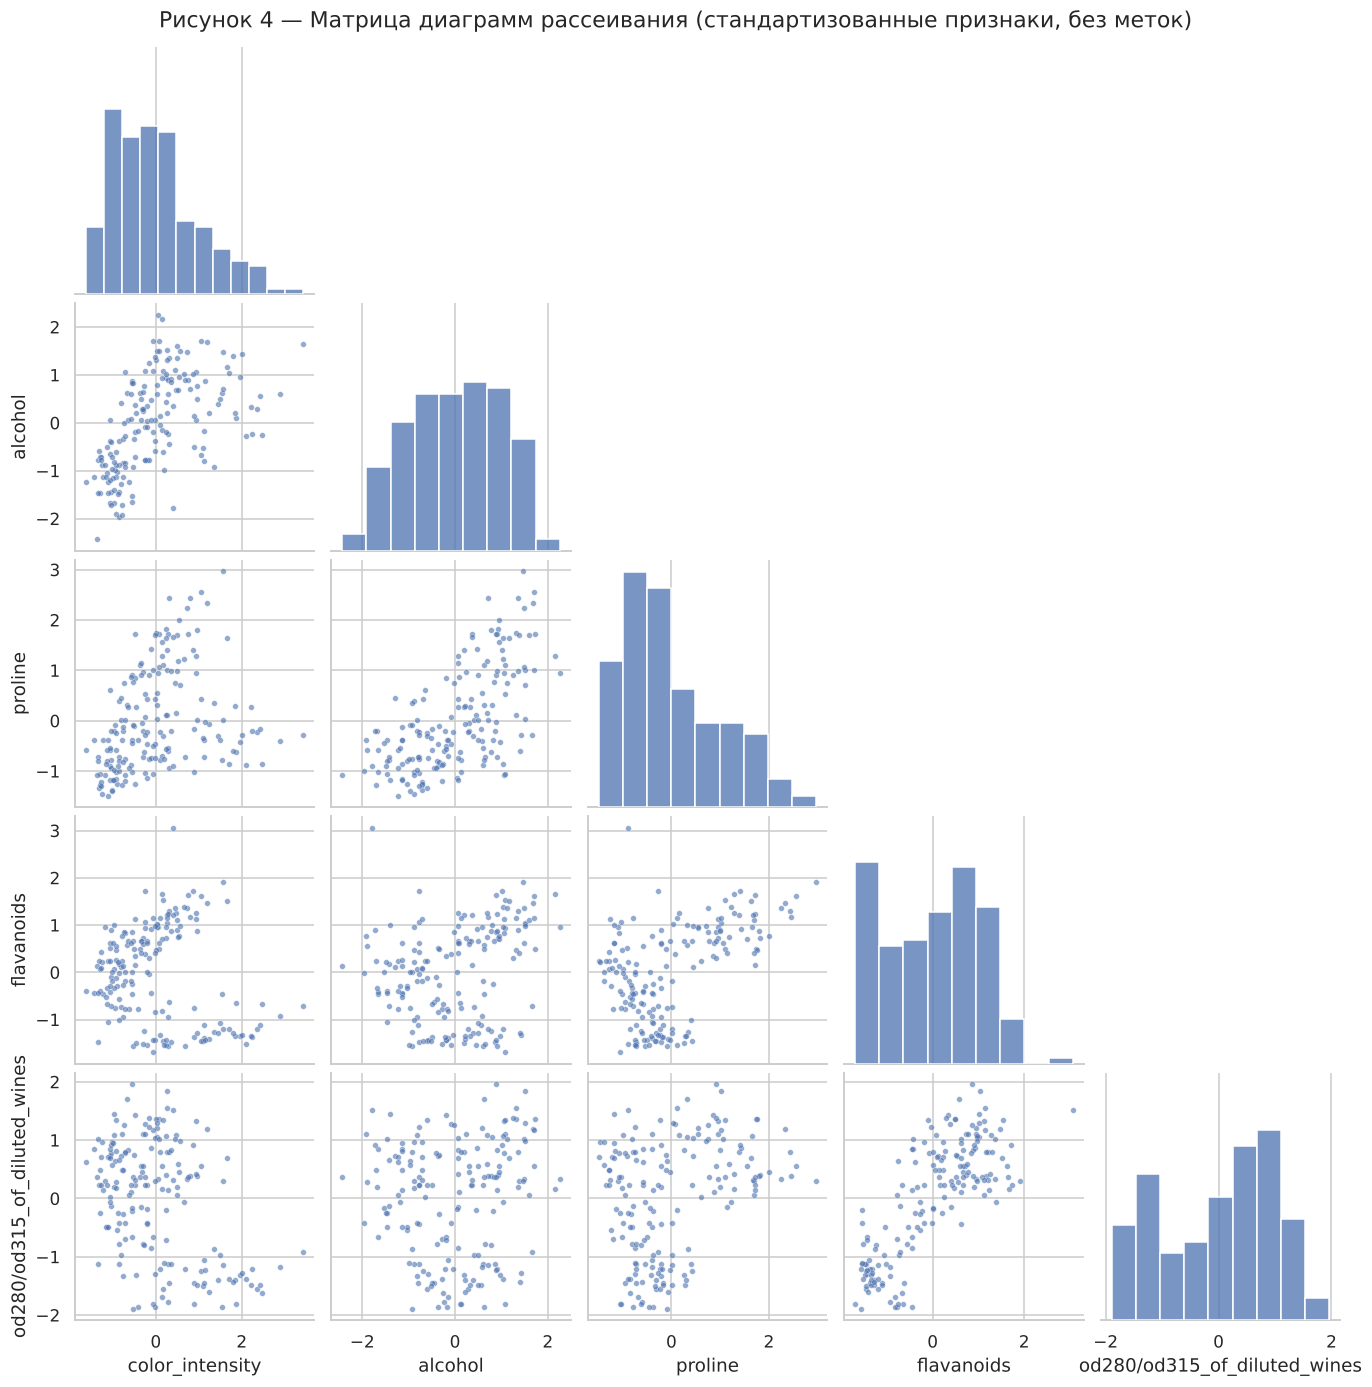

Признаки: ['color_intensity', 'alcohol', 'proline', 'flavanoids', 'od280/od315_of_diluted_wines']


In [11]:
# Матрица диаграмм рассеивания: 5 признаков с наибольшим вкладом в главные компоненты
TOP = info.sort_values("вклад в PC1-PC2", ascending=False).index[:5].tolist()
g = sns.pairplot(Xs_df[TOP], corner=True, plot_kws={"s": 14, "alpha": 0.6, "color": "#4C72B0"},
                 diag_kws={"color": "#4C72B0"})
g.figure.suptitle("Рисунок 4 — Матрица диаграмм рассеивания (стандартизованные признаки, без меток)", y=1.01)
plt.show()
print("Признаки:", TOP)

**Комментарий к рисунку 4.** Для матрицы выбраны 5 признаков с наибольшим вкладом в главные
компоненты. Наиболее информативные проекции:

- **`flavanoids` × `color_intensity`** — видны три группы: низкие флавоноиды и высокая интенсивность
  цвета (внизу справа), высокие флавоноиды при средней интенсивности (вверху), низкая интенсивность
  при средних флавоноидах (слева);
- **`flavanoids` × `od280/od315`** — вытянутое облако с отдельным плотным сгустком в левом нижнем углу;
- **`proline` × `alcohol`** — группа с высоким пролином и алкоголем отделяется от остальных.

Группы **компактные, примерно сферические, сопоставимого размера и плотности**, частично перекрываются;
изолированных «нитей» и колец нет.

**Ограничения двумерных проекций:** каждая диаграмма — «тень» 13-мерных данных на плоскость двух
признаков. Группы, разделённые в других признаках, на плоскости могут сливаться (на `alcohol` × `od280`
групп почти не видно), а три признака сразу на одном графике не показать. Поэтому вывод проверяется
на проекции главных компонент, которая учитывает все признаки.

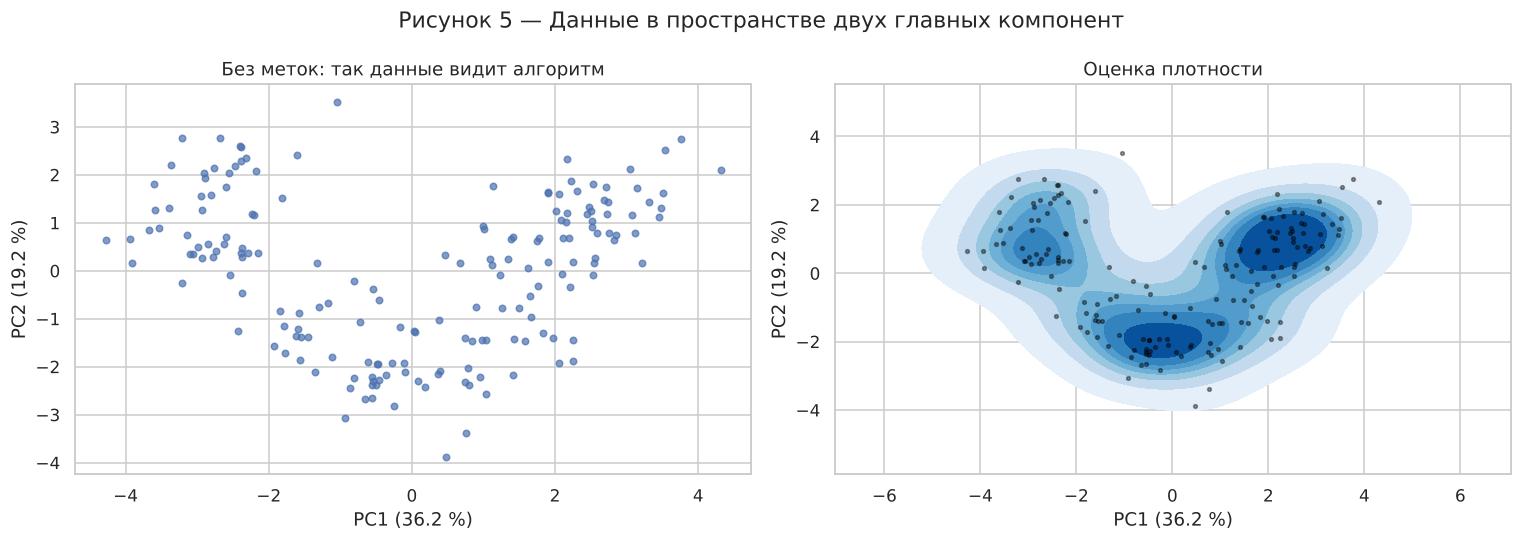

PC1 + PC2 сохраняют 55.4 % дисперсии


In [12]:
# Проекция на первые две главные компоненты — «вид сверху» на все 13 признаков сразу
pca2 = PCA(n_components=2, random_state=SEED).fit(Xs)
P = pca2.transform(Xs)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(P[:, 0], P[:, 1], s=18, color="#4C72B0", alpha=0.7)
axes[0].set_title("Без меток: так данные видит алгоритм")
sns.kdeplot(x=P[:, 0], y=P[:, 1], ax=axes[1], fill=True, cmap="Blues", levels=8)
axes[1].scatter(P[:, 0], P[:, 1], s=6, color="black", alpha=0.4)
axes[1].set_title("Оценка плотности")
for a in axes:
    a.set_xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]*100:.1f} %)")
    a.set_ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]*100:.1f} %)")
fig.suptitle("Рисунок 5 — Данные в пространстве двух главных компонент")
fig.tight_layout(); plt.show()
print(f"PC1 + PC2 сохраняют {pca2.explained_variance_ratio_.sum()*100:.1f} % дисперсии")

**Комментарий к рисунку 5.** В плоскости первых двух главных компонент (55,4 % дисперсии) видны **три
сгустка**, расположенные дугой: слева, внизу по центру и справа. На оценке плотности — три отдельных
максимума. Сгустки примерно **одинакового размера**, **выпуклые и близкие к сферическим**, между ними —
области пониженной плотности, но не пустые: границы размыты.

**Выбор методов на основе структуры данных:**

| Особенность | Следствие |
|---|---|
| Кластеры выпуклые, близкие к сферическим, сопоставимого размера | **K-means** — его модель (каждый кластер — шар вокруг центра) им соответствует |
| Число групп заранее неизвестно, хочется увидеть иерархию | **Иерархическая (Уорд)** — дендрограмма показывает структуру на всех уровнях; Уорд, как и K-means, минимизирует внутрикластерную дисперсию и формирует компактные кластеры |
| Плотность групп примерно одинакова, но границы размыты, объектов мало (178) в 13-мерном пространстве | **DBSCAN не подходит** — плотностные методы плохо работают при перекрытии и в высокой размерности (проверено в 4.5) |

## 4.2. Подбор оптимального количества кластеров

In [13]:
def cluster_metrics(Xa, labels, name):
    """Внутренние метрики; шум (метка -1) исключается. Если кластеров < 2 — метрики не определены."""
    mask = labels != -1
    k = len(set(labels[mask]))
    row = {"метод": name, "кластеров": k, "доля шума": 1 - mask.mean()}
    if k < 2 or mask.sum() <= k:                     # силуэт, CH и DB требуют 2 ≤ k < n
        row.update({"silhouette": np.nan, "Calinski-Harabasz": np.nan, "Davies-Bouldin": np.nan})
        return row
    row.update({"silhouette": silhouette_score(Xa[mask], labels[mask]),
                "Calinski-Harabasz": calinski_harabasz_score(Xa[mask], labels[mask]),
                "Davies-Bouldin": davies_bouldin_score(Xa[mask], labels[mask])})
    return row

Функция `cluster_metrics` считает внутренние метрики и **корректно обрабатывает вырожденные случаи**:
шумовые объекты DBSCAN (метка −1) исключаются, а если кластеров меньше двух (один кластер или всё — шум),
силуэт, Калински — Харабаш и Дэвис — Боулдин не рассчитываются (возвращается NaN) — эти метрики
определены только при 2 ≤ k < n.

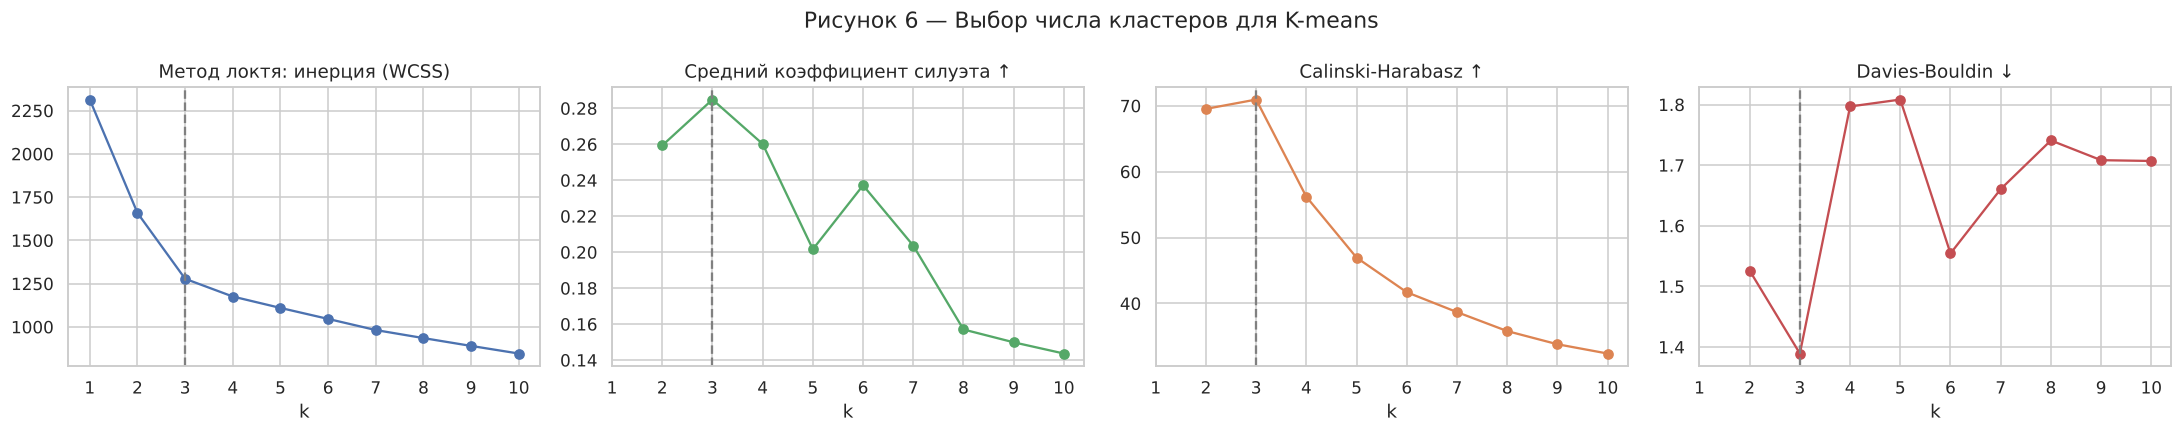

,inertia,silhouette,Calinski-Harabasz,Davies-Bouldin,"Δ inertia, %"
k,,,,,
1,2314.000,NaN,NaN,NaN,NaN
2,1658.759,0.259,69.523,1.526,28.316
3,1277.928,0.285,70.940,1.389,22.959
4,1175.428,0.260,56.181,1.797,8.021
5,1109.513,0.202,46.952,1.808,5.608
6,1046.002,0.237,41.701,1.554,5.724
7,981.595,0.204,38.686,1.661,6.157
8,935.201,0.157,35.805,1.741,4.726
9,889.893,0.150,33.807,1.708,4.845


In [14]:
# Перебор k для K-means: инерция (локоть), силуэт, Calinski-Harabasz, Davies-Bouldin
K_RANGE = range(1, 11)
sel = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=SEED).fit(Xs)
    r = {"k": k, "inertia": km.inertia_}
    if k > 1:
        r.update(cluster_metrics(Xs, km.labels_, "K-means"))
    sel.append(r)
sel = pd.DataFrame(sel).set_index("k").drop(columns=["метод", "кластеров", "доля шума"])

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
axes[0].plot(sel.index, sel["inertia"], "o-"); axes[0].set_title("Метод локтя: инерция (WCSS)")
axes[1].plot(sel.index[1:], sel["silhouette"][1:], "o-", color="#55A868"); axes[1].set_title("Средний коэффициент силуэта ↑")
axes[2].plot(sel.index[1:], sel["Calinski-Harabasz"][1:], "o-", color="#DD8452"); axes[2].set_title("Calinski-Harabasz ↑")
axes[3].plot(sel.index[1:], sel["Davies-Bouldin"][1:], "o-", color="#C44E52"); axes[3].set_title("Davies-Bouldin ↓")
for a in axes:
    a.axvline(3, ls="--", color="gray"); a.set_xlabel("k"); a.set_xticks(list(K_RANGE))
fig.suptitle("Рисунок 6 — Выбор числа кластеров для K-means"); fig.tight_layout(); plt.show()
sel["Δ inertia, %"] = (-sel["inertia"].pct_change() * 100)
sel.round(3)

**Комментарий к рисунку 6 и таблице.**

- **Метод локтя.** По вертикали — инерция (сумма квадратов расстояний объектов до центров своих
  кластеров). Переход 1 → 2 снижает её на 28,3 %, 2 → 3 — на 23,0 %, а 3 → 4 — только на 8,0 %, дальше
  по 5–6 %. **Излом при k = 3**: после него добавление кластеров почти не уменьшает разброс — новые кластеры
  уже дробят естественные группы.
- **Силуэт** максимален при k = 3 (0,285); при k = 2 — 0,259, при k = 4 — 0,260, дальше падает до 0,14.
- **Калински — Харабаш** максимален при k = 3 (70,9), **Дэвис — Боулдин** минимален при k = 3 (1,389).

**Все четыре критерия единогласно указывают на k = 3.** Значение силуэта 0,285 — «слабая, но реальная
структура»: кластеры есть, но их границы размыты (что видно и на рисунке 5).

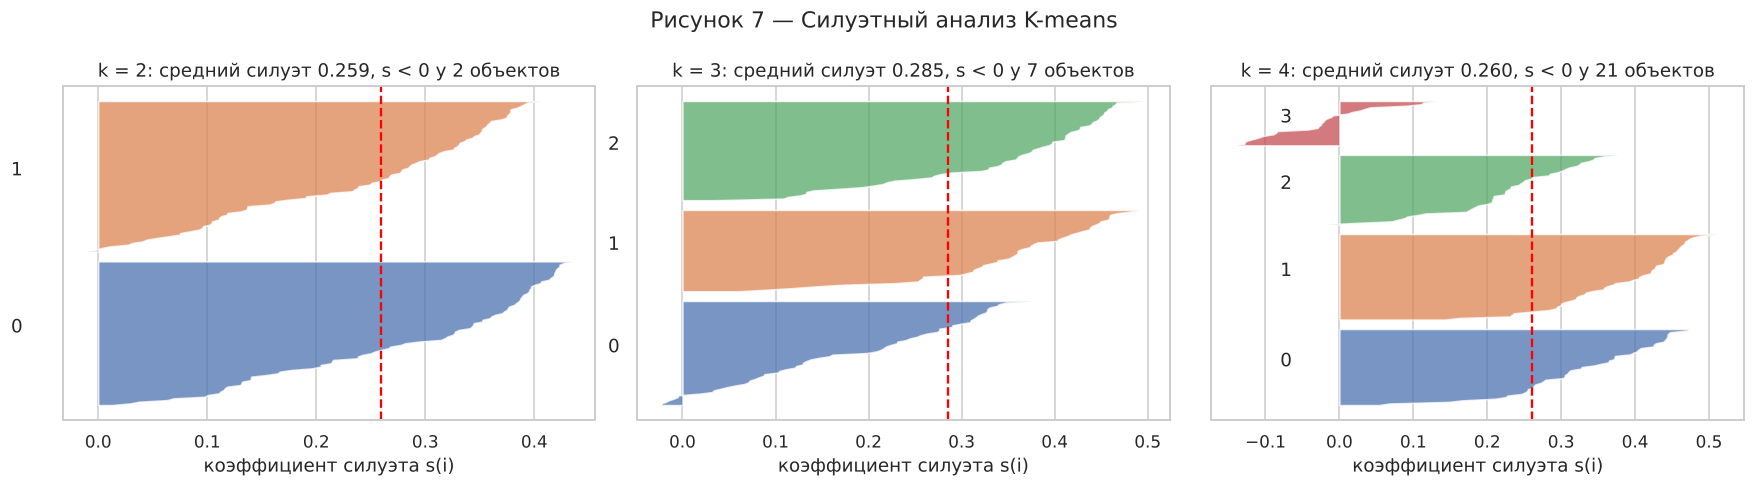

In [15]:
# Силуэтные диаграммы для k = 2, 3, 4: распределение s(i) по объектам каждого кластера
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, k in zip(axes, [2, 3, 4]):
    lab = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(Xs)
    s = silhouette_samples(Xs, lab)
    y0 = 0
    for c in range(k):
        sc = np.sort(s[lab == c])
        ax.fill_betweenx(np.arange(y0, y0 + len(sc)), 0, sc, alpha=0.75)
        ax.text(-0.08, y0 + len(sc) / 2, str(c))
        y0 += len(sc) + 5
    ax.axvline(s.mean(), ls="--", color="red")
    ax.set_title(f"k = {k}: средний силуэт {s.mean():.3f}, s < 0 у {(s < 0).sum()} объектов")
    ax.set_xlabel("коэффициент силуэта s(i)"); ax.set_yticks([])
fig.suptitle("Рисунок 7 — Силуэтный анализ K-means"); fig.tight_layout(); plt.show()

**Комментарий к рисунку 7 (силуэтные диаграммы).** Каждая «полоса» — объекты одного кластера,
отсортированные по s(i).

- **k = 2:** два кластера близкого размера, но средний силуэт ниже (0,259): каждый кластер вобрал по полторы естественные группы, и объекты внутри них разнородны.
- **k = 3:** все три кластера пересекают среднюю линию, размеры близки; отрицательный силуэт только
  у 7 объектов (4 %) — это пограничные вина. Средние силуэты кластеров: 0,18; 0,35; 0,34.
- **k = 4:** появляется кластер со средним силуэтом −0,03 — он «вырезан» из соседних групп и не имеет
  собственной структуры; отрицательных значений уже 21.

**Вывод: k = 3** — лучший вариант и по средней величине, и по форме силуэтов.

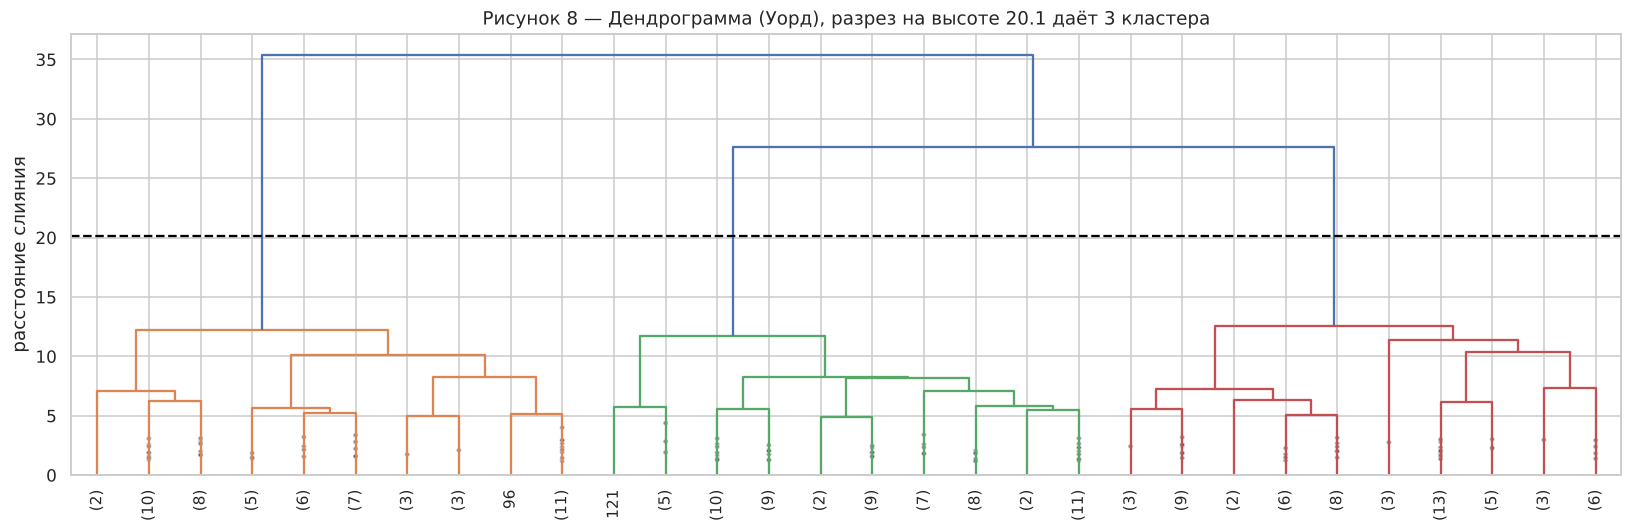

Высоты последних 6 слияний: [11.38 11.72 12.23 12.57 27.65 35.4 ]
Скачки высоты: [ 0.35  0.51  0.34 15.08  7.75]
Кластеров при разрезе на 20.1 : 3


In [16]:
# Иерархическая кластеризация: матрица слияний методом Уорда на евклидовых расстояниях
Z = linkage(Xs, method="ward", metric="euclidean")
fig, ax = plt.subplots(figsize=(15, 5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, ax=ax, color_threshold=Z[-3, 2] + 0.01,
           show_contracted=True)
cut = (Z[-3, 2] + Z[-2, 2]) / 2                       # уровень разреза между 2-м и 3-м последними слияниями
ax.axhline(cut, ls="--", color="black")
ax.set_title(f"Рисунок 8 — Дендрограмма (Уорд), разрез на высоте {cut:.1f} даёт 3 кластера")
ax.set_ylabel("расстояние слияния"); fig.tight_layout(); plt.show()
print("Высоты последних 6 слияний:", np.round(Z[-6:, 2], 2))
print("Скачки высоты:", np.round(np.diff(Z[-6:, 2]), 2))
print("Кластеров при разрезе на", round(cut, 1), ":", len(np.unique(fcluster(Z, t=cut, criterion="distance"))))

**Комментарий к рисунку 8 (дендрограмма).** По вертикали — расстояние (критерий Уорда), на котором
объединяются кластеры. Последние слияния происходят на высотах 12,6 → **27,7** → **35,4**: перед
объединением трёх групп в две расстояние скачком вырастает с 12,6 до 27,7 (**скачок 15,1** — самый
большой на всём дереве). Это значит, что на уровне трёх кластеров объединяются уже далёкие, разнородные
группы. **Горизонтальный разрез между 12,6 и 27,7** (на высоте 20,1) пересекает три вертикальные ветви —
итоговое разбиение на **3 кластера** (оранжевый, зелёный, красный). Размер ветвей близок — группы
сопоставимы по численности.

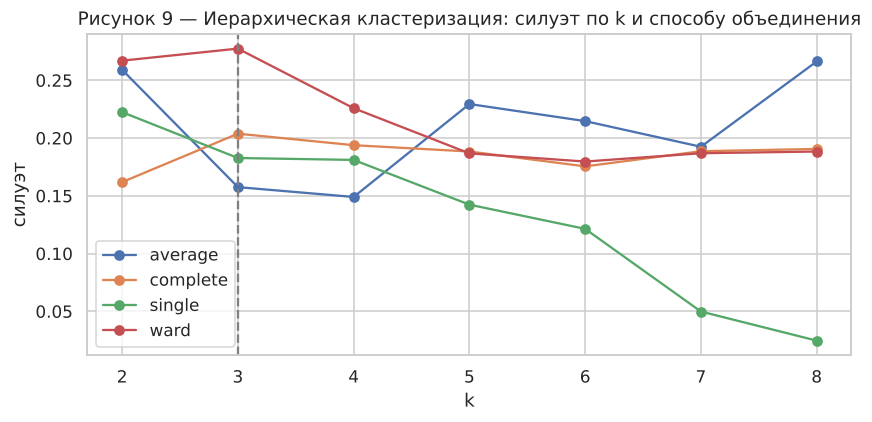

,метод,размеры,silhouette,Calinski-Harabasz,Davies-Bouldin
1,ward,"[64, 58, 56]",0.277,67.647,1.419
8,complete,"[69, 58, 51]",0.204,48.990,1.896
15,average,"[174, 3, 1]",0.158,4.031,1.030
22,single,"[174, 3, 1]",0.183,4.062,0.911


In [17]:
# Подбор k и способа объединения для иерархической кластеризации
rows = []
for link in ["ward", "complete", "average", "single"]:
    for k in range(2, 9):
        lab = AgglomerativeClustering(n_clusters=k, linkage=link).fit_predict(Xs)
        r = cluster_metrics(Xs, lab, link)
        r.update({"k": k, "размеры": sorted(np.bincount(lab).tolist(), reverse=True)})
        rows.append(r)
hier = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8, 4))
for link, g in hier.groupby("метод"):
    ax.plot(g.k, g.silhouette, "o-", label=link)
ax.set_xlabel("k"); ax.set_ylabel("силуэт"); ax.legend(); ax.axvline(3, ls="--", color="gray")
ax.set_title("Рисунок 9 — Иерархическая кластеризация: силуэт по k и способу объединения")
fig.tight_layout(); plt.show()
hier[hier.k == 3][["метод", "размеры", "silhouette", "Calinski-Harabasz", "Davies-Bouldin"]].round(3)

**Комментарий к рисунку 9 и таблице — выбор способа объединения кластеров.**

- **Уорд** — лучший силуэт при k = 3 (0,277) и сбалансированные кластеры 64 / 58 / 56.
- **Полная связь** (complete, расстояние по самым далёким объектам) — кластеры 69 / 58 / 51, силуэт 0,204.
- **Средняя (average) и одиночная (single) связь** дают **вырожденное разбиение 174 / 3 / 1**: они
  отделяют выбросы в отдельные «кластеры», а все остальные объекты сливаются в один. Single-связь
  к тому же создаёт эффект «цепочки». Их высокий Дэвис — Боулдин (0,91–1,03 — формально лучше!)
  обманчив: маленький далёкий кластер даёт большое межцентровое расстояние.

**Выбрано: метод Уорда, евклидово расстояние, k = 3.**

## 4.3. Построение моделей

| Параметр | K-means | Иерархическая |
|---|---|---|
| Число кластеров | `n_clusters=3` (локоть, силуэт, CH, DB) | `n_clusters=3` (дендрограмма, силуэт) |
| Инициализация | `init="k-means++"` — центры выбираются далеко друг от друга | — |
| Число запусков | `n_init=10` — 10 инициализаций, лучшая по инерции (защита от локальных минимумов) | — (алгоритм детерминирован) |
| Воспроизводимость | `random_state=42` | — |
| Объединение / метрика | — | `linkage="ward"`, `metric="euclidean"` |

In [18]:
K = 3
kmeans = KMeans(n_clusters=K, init="k-means++", n_init=10, max_iter=300, random_state=SEED)
hier_model = AgglomerativeClustering(n_clusters=K, linkage="ward", metric="euclidean")

labels_km = kmeans.fit_predict(Xs)          # метки K-means, форма (178,)
labels_hc = hier_model.fit_predict(Xs)      # метки иерархической кластеризации, форма (178,)

print("Форма меток:", labels_km.shape, labels_hc.shape)
print("K-means: кластеров", len(np.unique(labels_km)), "| размеры", np.bincount(labels_km).tolist(),
      "| итераций", kmeans.n_iter_, "| inertia", round(kmeans.inertia_, 1))
print("Иерархическая: кластеров", len(np.unique(labels_hc)), "| размеры", np.bincount(labels_hc).tolist())

Форма меток: (178,) (178,)
K-means: кластеров 3 | размеры [65, 51, 62] | итераций 7 | inertia 1277.9
Иерархическая: кластеров 3 | размеры [58, 56, 64]


K-means сошёлся за 7 итераций, инерция 1 277,9; размеры кластеров 65 / 51 / 62. Иерархическая
кластеризация — 58 / 56 / 64. Обе модели вернули массив меток размером (178,) — по одной метке
на каждое вино. Нумерация кластеров у методов произвольная и не совпадает с номерами сортов.

## 4.4. Метрики качества

In [19]:
def centroids(Xa, labels):
    """Центры = средние объектов кластера (для иерархической — вычисляем сами)."""
    ks = np.unique(labels[labels != -1])
    return np.vstack([Xa[labels == k].mean(0) for k in ks])

def compactness(Xa, labels):
    """По каждому кластеру: среднее попарное расстояние (внутрикластерное),
       среднее расстояние до центра (компактность), сумма квадратов до центра (вклад в инерцию)."""
    rows = []
    for k in np.unique(labels[labels != -1]):
        P_ = Xa[labels == k]
        c = P_.mean(0)
        d = np.linalg.norm(P_ - c, axis=1)
        rows.append({"кластер": k, "объектов": len(P_), "ср. попарное расстояние": pdist(P_).mean(),
                     "ср. расстояние до центра": d.mean(), "макс. до центра (радиус)": d.max(),
                     "SSE": (d ** 2).sum()})
    return pd.DataFrame(rows).set_index("кластер")

res = pd.DataFrame([cluster_metrics(Xs, labels_km, "K-means (k=3)"),
                    cluster_metrics(Xs, labels_hc, "Иерархическая, Уорд (k=3)")]).set_index("метод")
for name, lab in [("K-means (k=3)", labels_km), ("Иерархическая, Уорд (k=3)", labels_hc)]:
    cp = compactness(Xs, lab)
    D = cdist(centroids(Xs, lab), centroids(Xs, lab))
    res.loc[name, "SSE (инерция)"] = cp["SSE"].sum()
    res.loc[name, "ср. внутрикл. расстояние"] = (cp["ср. попарное расстояние"] * cp["объектов"]).sum() / cp["объектов"].sum()
    res.loc[name, "мин. расст. между центрами"] = D[np.triu_indices(len(D), 1)].min()
    res.loc[name, "Dunn (по центрам)"] = D[np.triu_indices(len(D), 1)].min() / (2 * cp["макс. до центра (радиус)"].max())
print("Таблица 4 — Внутренние метрики качества")
res.round(3)

Таблица 4 — Внутренние метрики качества


,кластеров,доля шума,silhouette,Calinski-Harabasz,Davies-Bouldin,SSE (инерция),ср. внутрикл. расстояние,мин. расст. между центрами,Dunn (по центрам)
метод,,,,,,,,,
K-means (k=3),3,0.0,0.285,70.940,1.389,1277.928,3.637,3.596,0.292
"Иерархическая, Уорд (k=3)",3,0.0,0.277,67.647,1.419,1305.049,3.670,3.545,0.288


**Интерпретация таблицы 4 (внутренние метрики).**

- **Силуэт:** K-means 0,285, Уорд 0,277 — структура слабая, но реальная, у K-means немного чётче.
- **Калински — Харабаш:** 70,9 против 67,6 — у K-means отношение межкластерного разброса к внутрикластерному
  выше на 5 %.
- **Дэвис — Боулдин:** 1,389 против 1,419 — кластеры K-means чуть лучше отделены относительно своего размера.
- **SSE (инерция):** 1 277,9 у K-means против 1 305,0 у Уорда — ожидаемо, ведь K-means напрямую
  минимизирует именно эту величину.
- **Среднее внутрикластерное расстояние** (среднее попарное расстояние объектов одного кластера,
  взвешенное по размерам) — 3,64 и 3,67; **минимальное расстояние между центрами** — 3,60 и 3,54.
  Внутрикластерные расстояния сопоставимы с межцентровыми — именно поэтому силуэт невысокий: кластеры
  соприкасаются.
- **Индекс Данна** (по центрам: мин. межцентровое расстояние / (2 · макс. радиус)) ≈ 0,29 у обоих —
  < 1, то есть «шары» кластеров перекрываются.

По всем внутренним метрикам **K-means немного лучше**, но разница мала — методы дают близкие разбиения.

In [20]:
for name, lab in [("K-means", labels_km), ("Иерархическая (Уорд)", labels_hc)]:
    print(f"\n{name}: компактность кластеров (стандартизованное пространство)")
    print(compactness(Xs, lab).round(3).to_string())
    D = pd.DataFrame(cdist(centroids(Xs, lab), centroids(Xs, lab)),
                     index=[f"C{i}" for i in range(K)], columns=[f"C{i}" for i in range(K)])
    print(f"Расстояния между центрами кластеров ({name}):")
    print(D.round(3).to_string())


K-means: компактность кластеров (стандартизованное пространство)
         объектов  ср. попарное расстояние  ср. расстояние до центра  макс. до центра (радиус)      SSE
кластер                                                                                                
0              65                    4.010                     2.789                     5.396  561.854
1              51                    3.493                     2.445                     4.960  328.198
2              62                    3.364                     2.337                     6.162  387.877
Расстояния между центрами кластеров (K-means):
       C0     C1     C2
C0  0.000  3.973  3.596
C1  3.973  0.000  5.029
C2  3.596  5.029  0.000

Иерархическая (Уорд): компактность кластеров (стандартизованное пространство)
         объектов  ср. попарное расстояние  ср. расстояние до центра  макс. до центра (радиус)      SSE
кластер                                                                                 

**Компактность и расстояния между кластерами.**

- **Компактность** определена как среднее евклидово расстояние объектов до центра своего кластера
  (центр — среднее объектов кластера), **внутрикластерное расстояние** — как среднее попарное расстояние
  между объектами кластера. В K-means самый «рыхлый» — кластер 0 (65 вин, 2,79 до центра, 4,01 попарно),
  самые плотные — кластеры 1 и 2 (2,34–2,45).
- **Межкластерные расстояния** — между центрами: ближе всего кластеры 0 и 2 (3,60), дальше всего 1 и 2
  (5,03). Кластер 0 лежит «между» двумя другими — это видно на рисунке 12, где он находится в центре дуги.
- У иерархической кластеризации картина та же: 3,55 / 3,87 / 4,85.

In [21]:
def jaccard_pairs(a, b):
    """Индекс Жаккара по парам объектов: J = a / (a + b + c), где
       a — пары вместе в обеих разметках, b и c — вместе только в одной.
       Считается по парам, поэтому не зависит от нумерации кластеров."""
    (tn, fp), (fn, tp) = pair_confusion_matrix(a, b) // 2
    return tp / (tp + fp + fn)

ext = []
for name, lab in [("K-means (k=3)", labels_km), ("Иерархическая, Уорд (k=3)", labels_hc)]:
    ext.append({"метод": name, "Rand": rand_score(y_true, lab), "ARI": adjusted_rand_score(y_true, lab),
                "Jaccard": jaccard_pairs(y_true, lab), "Fowlkes-Mallows": fowlkes_mallows_score(y_true, lab),
                "NMI": normalized_mutual_info_score(y_true, lab), "однородность": homogeneity_score(y_true, lab),
                "полнота": completeness_score(y_true, lab)})
ext = pd.DataFrame(ext).set_index("метод")
print("Таблица 5 — Внешние метрики (сравнение с истинными сортами)")
ext.round(3)

Таблица 5 — Внешние метрики (сравнение с истинными сортами)


,Rand,ARI,Jaccard,Fowlkes-Mallows,NMI,однородность,полнота
метод,,,,,,,
K-means (k=3),0.954,0.897,0.872,0.932,0.876,0.879,0.873
"Иерархическая, Уорд (k=3)",0.906,0.790,0.755,0.860,0.786,0.790,0.783


**Интерпретация таблицы 5 (внешние метрики).** Сравниваются две разметки: **истинные сорта** `y_true`
и **метки кластеров**.

- **ARI = 0,897** у K-means и 0,790 у Уорда. ARI корректирует индекс Rand на случайное совпадение:
  0 — разбиение не лучше случайного, 1 — полное совпадение. 0,9 — **очень высокое совпадение**:
  K-means почти без ошибок восстановил сорта, не зная их.
- **Rand = 0,954 / 0,906** — доля пар объектов, по которым разметки согласны («вместе в обеих»
  или «раздельно в обеих»). Он всегда завышен (даже случайное разбиение даёт ≈ 0,5–0,6), поэтому основной —
  ARI.
- **Жаккар = 0,872 / 0,755** — считается **по парам объектов**: J = a / (a + b + c), где a — пары,
  попавшие в один кластер и в один сорт, b и c — пары, объединённые только в одной из разметок. Поэтому
  произвольная нумерация кластеров на него не влияет — пары «вместе / раздельно» от перестановки
  номеров не меняются.
- **NMI = 0,876 / 0,786**, однородность и полнота близки — кластеры почти «чистые» и почти не дробят сорта.

**По внешним метрикам K-means заметно лучше** (ARI выше на 0,11).

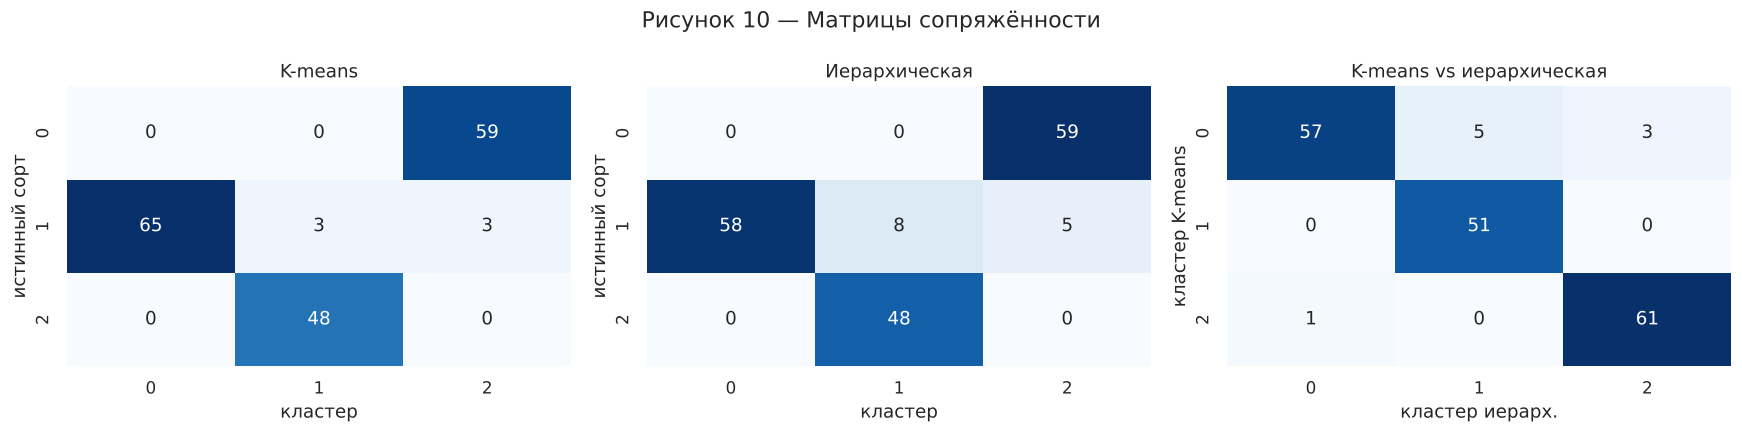

Согласованность двух методов между собой: ARI = 0.853


In [22]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, a, b, ylab) in zip(axes, [("K-means", y_true, labels_km, "истинный сорт"),
                                         ("Иерархическая", y_true, labels_hc, "истинный сорт"),
                                         ("K-means vs иерархическая", labels_km, labels_hc, "кластер K-means")]):
    sns.heatmap(contingency_matrix(a, b), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(name); ax.set_ylabel(ylab); ax.set_xlabel("кластер" if "vs" not in name else "кластер иерарх.")
fig.suptitle("Рисунок 10 — Матрицы сопряжённости"); fig.tight_layout(); plt.show()
print("Согласованность двух методов между собой: ARI =", round(adjusted_rand_score(labels_km, labels_hc), 3))

**Комментарий к рисунку 10 (матрицы сопряжённости).**

- **K-means:** сорт 0 целиком в кластере 2 (59 из 59), сорт 2 целиком в кластере 1 (48 из 48), сорт 1 —
  65 из 71 в кластере 0, по 3 вина ушли в соседние кластеры. **Ошибаются только 6 вин из 178 (3,4 %)** —
  все из сорта 1.
- **Иерархическая:** сорта 0 и 2 тоже восстановлены полностью, но из сорта 1 ошибочно отнесены 13 вин
  (8 и 5) — **7,3 %**.
- **K-means против иерархической:** методы согласны на 169 винах из 178, ARI между ними 0,853. Расхождения —
  те же пограничные вина сорта 1.

Сорт 1 — «промежуточный»: на рисунке 12 он лежит в центре дуги между двумя другими, поэтому его крайние
представители попадают в соседние кластеры.

## 4.5. Влияние параметров и устойчивость кластеров

In [23]:
# Влияние параметров K-means: k, способ инициализации и число запусков n_init
rows = []
for init in ["k-means++", "random"]:
    for n_init in [1, 10]:
        for seed in range(20):                          # 20 разных random_state
            km_ = KMeans(n_clusters=3, init=init, n_init=n_init, random_state=seed).fit(Xs)
            rows.append({"init": init, "n_init": n_init, "seed": seed, "inertia": km_.inertia_,
                         "ARI": adjusted_rand_score(y_true, km_.labels_)})
st = pd.DataFrame(rows)
print("Таблица 6 — Устойчивость K-means (k = 3) к инициализации, 20 запусков")
st.groupby(["init", "n_init"]).agg(inertia_min=("inertia", "min"), inertia_max=("inertia", "max"),
                                    inertia_std=("inertia", "std"), ARI_min=("ARI", "min"),
                                    ARI_mean=("ARI", "mean")).round(3)

Таблица 6 — Устойчивость K-means (k = 3) к инициализации, 20 запусков


inertia_min  inertia_max  inertia_std  ARI_min  ARI_mean
init      n_init                                                          
k-means++ 1          1277.928     1282.464        1.380    0.846     0.889
          10         1277.928     1278.761        0.186    0.897     0.898
random    1          1277.928     1595.806       70.902    0.322     0.864
          10         1277.928     1277.928        0.000    0.897     0.897

**Таблица 6 — влияние `init` и `n_init` на K-means** (20 запусков с разными `random_state`).

- **`init="random"`, `n_init=1`** — самый неустойчивый вариант: инерция от 1 278 до 1 596, ARI падает
  до 0,32. Случайные стартовые центры могут попасть в один сгусток, и алгоритм застревает в **локальном
  минимуме** — один кластер «разрезается» пополам, а два других сливаются.
- **`k-means++`, `n_init=1`** — гораздо лучше (инерция 1 278–1 282, ARI ≥ 0,85): умная инициализация
  разносит стартовые центры.
- **`n_init=10`** при любой инициализации даёт **один и тот же глобальный результат** (инерция 1 277,9,
  ARI 0,897): из 10 запусков выбирается лучший по инерции.

Именно поэтому в модели выбраны `init="k-means++"` и `n_init=10`. **Влияние k** показано на рисунке 6:
при k = 3 все метрики оптимальны, ARI = 0,90; при k = 2 сливаются два сорта (ARI 0,37), при k ≥ 4
естественные группы дробятся (ARI 0,77 → 0,42 при k = 8).

In [24]:
# Устойчивость кластеров к выборке: 100 бутстрэп-выборок, сравнение с кластеризацией по всем данным
rng = np.random.default_rng(SEED)
boot = {"K-means": [], "Иерархическая": []}
for _ in range(100):
    idx = rng.choice(len(Xs), len(Xs), replace=True)
    boot["K-means"].append(adjusted_rand_score(labels_km[idx],
                           KMeans(3, n_init=10, random_state=SEED).fit_predict(Xs[idx])))
    boot["Иерархическая"].append(adjusted_rand_score(labels_hc[idx],
                           AgglomerativeClustering(3, linkage="ward").fit_predict(Xs[idx])))
pd.DataFrame(boot).describe().loc[["mean", "std", "min", "50%"]].round(3)

,K-means,Иерархическая
mean,0.932,0.822
std,0.056,0.091
min,0.702,0.483
50%,0.945,0.824


**Устойчивость к выборке.** На 100 бутстрэп-выборках (выборки того же размера с возвращением)
кластеризация повторялась и сравнивалась с исходной на тех же объектах. Средний ARI: **K-means 0,93**
(медиана 0,95), **иерархическая 0,82** (медиана 0,82, минимум 0,48). Кластеры K-means **устойчивы**
к изменению состава данных и к выбросам; иерархическая кластеризация чувствительнее — ошибка слияния
на нижнем уровне дерева не исправляется на верхних.

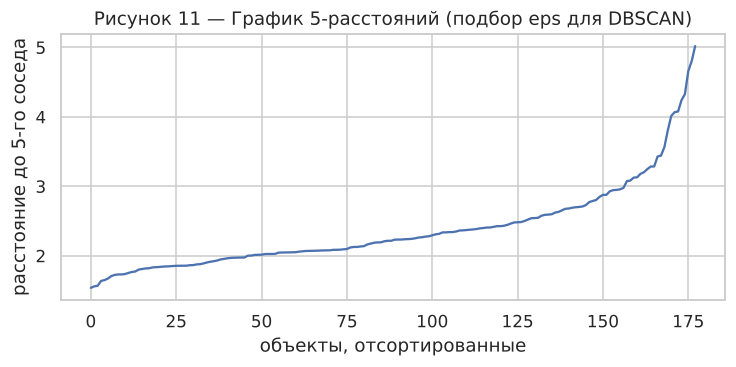

,eps,min_samples,кластеров,доля шума,silhouette,ARI
0,1.5,3,8,0.826,0.331,0.040
1,1.5,5,0,1.000,NaN,NaN
2,1.5,10,0,1.000,NaN,NaN
3,2.0,3,5,0.360,0.211,0.287
4,2.0,5,5,0.478,0.240,0.220
5,2.0,10,1,0.781,NaN,0.243
6,2.3,3,3,0.180,0.225,0.399
7,2.3,5,2,0.236,0.331,0.384
8,2.3,10,2,0.360,0.364,0.282
9,2.6,3,1,0.112,NaN,-0.000


In [25]:
# Для сравнения: DBSCAN — почему он не подходит этим данным (исследование eps и min_samples)
k_dist = np.sort(NearestNeighbors(n_neighbors=5).fit(Xs).kneighbors(Xs)[0][:, -1])
rows = []
for eps in [1.5, 2.0, 2.3, 2.6, 3.0]:
    for ms in [3, 5, 10]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(Xs)
        r = cluster_metrics(Xs, lab, "DBSCAN")
        r.update({"eps": eps, "min_samples": ms,
                  "ARI": adjusted_rand_score(y_true, lab) if r["кластеров"] > 0 else np.nan})
        rows.append(r)
db = pd.DataFrame(rows)[["eps", "min_samples", "кластеров", "доля шума", "silhouette", "ARI"]]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(k_dist); ax.set_title("Рисунок 11 — График 5-расстояний (подбор eps для DBSCAN)")
ax.set_xlabel("объекты, отсортированные"); ax.set_ylabel("расстояние до 5-го соседа")
fig.tight_layout(); plt.show()
db.round(3)

**DBSCAN (для обоснования выбора методов).** На графике 5-расстояний нет резкого «колена» — плотность
данных плавно меняется, единого порога eps не существует. В таблице:

- при eps = 1,5 почти всё — шум (83–100 %); при eps = 1,5 и min_samples = 5 — **все объекты признаны
  шумом**, метрики не определены (NaN);
- при eps ≥ 2,6 почти всё сливается в **один кластер** — силуэт не определён;
- лучший вариант (eps = 2,3, min_samples = 5) — 2 кластера, 24 % шума, ARI всего 0,38.

Плотностной метод не находит три группы: кластеры соприкасаются, а в 13-мерном пространстве при 178
объектах плотность оценивается плохо (проклятие размерности). Это подтверждает выбор K-means и Уорда.

# 5. Визуализация и интерпретация кластеров

Кластеризация выполнена **в исходном 13-мерном стандартизованном пространстве**; PCA применяется только
для рисунка — двумерная проекция сохраняет 55,4 % дисперсии. Центры кластеров (красные крестики)
переведены в пространство PCA тем же преобразованием `pca2.transform`.

Доля дисперсии PC1, PC2: [0.362 0.192] | вместе: 0.554


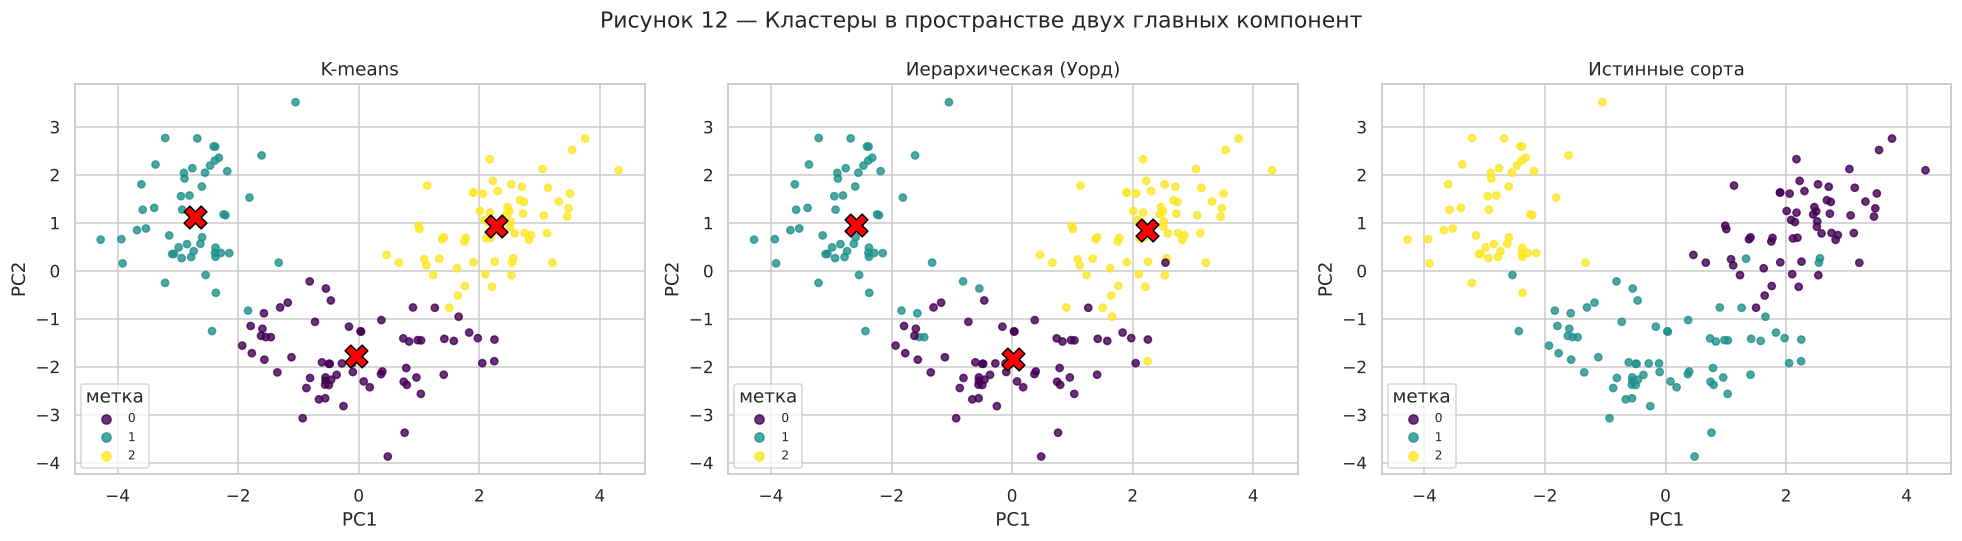

In [26]:
# Визуализация: кластеризация выполнена в исходном 13-мерном пространстве, PCA — только для рисунка
pca_full = PCA().fit(Xs)
print("Доля дисперсии PC1, PC2:", pca_full.explained_variance_ratio_[:2].round(3),
      "| вместе:", pca_full.explained_variance_ratio_[:2].sum().round(3))
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (title, lab) in zip(axes, [("K-means", labels_km), ("Иерархическая (Уорд)", labels_hc), ("Истинные сорта", y_true)]):
    sc = ax.scatter(P[:, 0], P[:, 1], c=lab, cmap="viridis", s=22, alpha=0.8)
    if title != "Истинные сорта":
        cent2 = pca2.transform(centroids(Xs, lab))
        ax.scatter(cent2[:, 0], cent2[:, 1], c="red", marker="X", s=220, edgecolor="black")   # центры кластеров
    ax.set_title(title); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
    ax.legend(*sc.legend_elements(), title="метка", loc="lower left", fontsize=8)
fig.suptitle("Рисунок 12 — Кластеры в пространстве двух главных компонент"); fig.tight_layout(); plt.show()

**Комментарий к рисунку 12.** Оба метода выделили три группы, совпадающие с тремя сгустками дуги:
слева, в центре внизу и справа. Сравнение с правой панелью (истинные сорта; цвета у панелей не связаны —
нумерация кластеров произвольная) показывает почти полное совпадение. Различия методов — на обеих границах
центральной группы: иерархическая кластеризация отнесла 8 её вин к левому кластеру и 5 — к правому
(у K-means — по 3). Центры K-means лежат в «середине» сгустков.

In [27]:
# Характеристики кластеров в исходных единицах: центры K-means переводятся обратно inverse_transform
centers_orig = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=FEATURES)
centers_orig.index = [f"кластер {i} (n={n})" for i, n in enumerate(np.bincount(labels_km))]
prof = centers_orig.T
prof["среднее по всем"] = X.mean()
print("Таблица 7 — Центры кластеров K-means в исходных единицах")
prof.round(2)

Таблица 7 — Центры кластеров K-means в исходных единицах


,кластер 0 (n=65),кластер 1 (n=51),кластер 2 (n=62),среднее по всем
alcohol,12.25,13.13,13.68,13.00
malic_acid,1.90,3.31,2.00,2.34
ash,2.23,2.42,2.47,2.37
alcalinity_of_ash,20.06,21.24,17.46,19.49
magnesium,92.74,98.67,107.97,99.74
total_phenols,2.25,1.68,2.85,2.30
flavanoids,2.05,0.82,3.00,2.03
nonflavanoid_phenols,0.36,0.45,0.29,0.36
proanthocyanins,1.62,1.15,1.92,1.59
color_intensity,2.97,7.23,5.45,5.06


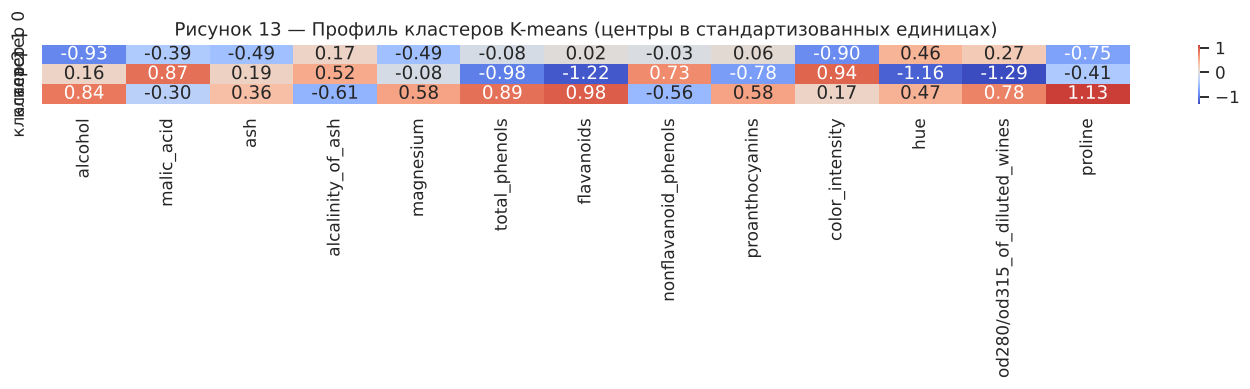

In [28]:
# Профиль кластеров в z-оценках: насколько центр кластера выше/ниже среднего по выборке (в σ)
zc = pd.DataFrame(kmeans.cluster_centers_, columns=FEATURES, index=[f"кластер {i}" for i in range(K)])
fig, ax = plt.subplots(figsize=(13, 3.6))
sns.heatmap(zc, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Рисунок 13 — Профиль кластеров K-means (центры в стандартизованных единицах)")
fig.tight_layout(); plt.show()

**Интерпретация кластеров (таблица 7 и рисунок 13, K-means).** Центры переведены в исходные единицы
через `scaler.inverse_transform`:

| Кластер | Размер | Отличительные признаки | Сорт |
|---|---|---|---|
| **2** — «крепкие, насыщенные фенолами» | 62 | **пролин 1 100** (+1,1σ), алкоголь 13,7 %, флавоноиды 3,0, общие фенолы 2,85, магний 108 — всё выше среднего; щёлочность золы ниже | сорт 0 (59 из 59) |
| **1** — «тёмные, кислые, бедные фенолами» | 51 | **интенсивность цвета 7,2** (+0,9σ), **яблочная кислота 3,3**, флавоноиды **0,82** (−1,2σ), оттенок 0,69, OD280 1,70 — низкие | сорт 2 (48 из 48) |
| **0** — «лёгкие, светлые» | 65 | **алкоголь 12,25 %** (−0,9σ), **интенсивность цвета 2,97** (−0,9σ), пролин 510, магний 93 — ниже среднего; фенолы около среднего | сорт 1 (65 из 71) |

Главные признаки, по которым различаются группы, — пролин, флавоноиды, интенсивность цвета, алкоголь
и OD280. Это совпадает с результатом оценки информативности (раздел 2): они же имеют наибольший вклад
в главные компоненты и наибольшую F-статистику. Слабее всего группы
различаются по золе и магнию (|z| ≤ 0,6).

In [29]:
summary = res[["кластеров", "silhouette", "Calinski-Harabasz", "Davies-Bouldin", "SSE (инерция)",
               "ср. внутрикл. расстояние", "мин. расст. между центрами"]].join(ext[["ARI", "Rand", "Jaccard", "NMI"]])
summary["размеры кластеров"] = [sorted(np.bincount(labels_km).tolist(), reverse=True),
                                sorted(np.bincount(labels_hc).tolist(), reverse=True)]
summary["устойчивость (бутстрэп ARI)"] = [np.mean(boot["K-means"]), np.mean(boot["Иерархическая"])]
print("Таблица 8 — Итоговое сравнение методов")
summary.T

Таблица 8 — Итоговое сравнение методов


метод,K-means (k=3),"Иерархическая, Уорд (k=3)"
кластеров,3,3
silhouette,0.284859,0.277444
Calinski-Harabasz,70.940008,67.647468
Davies-Bouldin,1.389188,1.418592
SSE (инерция),1277.928489,1305.048695
ср. внутрикл. расстояние,3.637097,3.669683
мин. расст. между центрами,3.596396,3.544767
ARI,0.897495,0.789933
Rand,0.954294,0.906494
Jaccard,0.872453,0.754623


**Итоговое сравнение (таблица 8).** K-means лучше по всем показателям: внутренним (силуэт 0,285 против
0,277, CH 70,9 против 67,6, DB 1,39 против 1,42), внешним (ARI 0,90 против 0,79, Жаккар 0,87 против 0,75)
и по устойчивости (бутстрэп ARI 0,93 против 0,82). Размеры кластеров у обоих методов сбалансированы.
Разница по внутренним метрикам мала, а по внешним и по устойчивости — существенна.

# 6. Заключение

1. **Данные:** 178 вин, 13 химических признаков, без пропусков; признаки в разных шкалах, частично
   скошены, у 5–10 % объектов умеренные выбросы (оставлены — это реальные вина). Многовершинные
   распределения и статистика Хопкинса H = 0,71 подтверждают наличие кластерной структуры.
2. **Предобработка:** стандартизация `StandardScaler` — признаки в разных единицах, распределения близки
   к симметричным, выбросов немного.
3. **Число кластеров k = 3** выбрано единогласно: локоть инерции, максимум силуэта (0,285), максимум
   Калински — Харабаша, минимум Дэвиса — Боулдина и самый большой скачок на дендрограмме.
4. **Методы:** K-means (k-means++, n_init = 10) и иерархическая кластеризация Уорда — по форме данных
   (компактные выпуклые группы сопоставимого размера). Average- и single-связь вырождаются (174 / 3 / 1),
   DBSCAN не находит три группы (кластеры соприкасаются, высокая размерность).
5. **Качество:** **K-means лучше** — силуэт 0,285, ARI 0,897 (ошибки только у 6 вин из 178), бутстрэп-
   устойчивость 0,93; иерархическая — силуэт 0,277, ARI 0,790 (13 ошибок), устойчивость 0,82. Методы
   согласны между собой на 169 винах (ARI 0,85).
6. **Влияние параметров:** случайная инициализация с одним запуском приводит K-means в локальные минимумы
   (ARI до 0,32); k-means++ и n_init = 10 гарантируют глобальное решение. Способ объединения критичен
   для иерархической кластеризации: только Уорд и полная связь дают осмысленные группы.
7. **Интерпретация:** выделены три химических типа вин — «крепкие, богатые пролином и фенолами»,
   «тёмные, кислые, бедные фенолами» и «лёгкие, светлые»; они почти точно соответствуют трём сортам
   винограда.

**Применимость методов к данному типу данных.** Для небольших наборов числовых признаков с компактными
выпуклыми группами сопоставимого размера лучше всего подходит K-means: он прост, быстр, устойчив
и даёт интерпретируемые центры. Иерархическая кластеризация полезна как инструмент выбора k
(дендрограмма), но менее устойчива. Плотностные методы (DBSCAN) уместны при группах произвольной формы
с явными разрывами плотности и низкой размерности — здесь этих условий нет. Ограничение всех методов —
невысокий силуэт (0,28): группы перекрываются, и пограничные вина (в основном сорт 1) кластеризуются
неоднозначно.

# 7. Список источников

1. Wine Data Set [Электронный ресурс] // UCI Machine Learning Repository. —
   URL: https://archive.ics.uci.edu/dataset/109/wine (дата обращения: 10.11.2026).
2. Scikit-learn User Guide: Clustering; Clustering performance evaluation [Электронный ресурс]. —
   URL: https://scikit-learn.org/stable/modules/clustering.html
3. SciPy: Hierarchical clustering (scipy.cluster.hierarchy) [Электронный ресурс]. —
   URL: https://docs.scipy.org/doc/scipy/reference/cluster.hierarchy.html
4. Rousseeuw P. J. Silhouettes: a graphical aid to the interpretation and validation of cluster analysis //
   Journal of Computational and Applied Mathematics. — 1987. — Vol. 20. — P. 53–65.
5. Hubert L., Arabie P. Comparing partitions // Journal of Classification. — 1985. — Vol. 2. — P. 193–218.
6. Хасти Т., Тибширани Р., Фридман Дж. Основы статистического обучения. — 2-е изд. — М.: Диалектика, 2020.
7. Жерон О. Прикладное машинное обучение с помощью Scikit-Learn, Keras и TensorFlow. — 2-е изд. —
   М.: Диалектика, 2020.

# 8. Приложение. Листинг программного кода

```python
# ---- imports ----
# Импорт библиотек
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist, cdist

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import (silhouette_score, silhouette_samples, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score, rand_score,
                             normalized_mutual_info_score, homogeneity_score,
                             completeness_score, v_measure_score, fowlkes_mallows_score)
from sklearn.metrics.cluster import contingency_matrix, pair_confusion_matrix

warnings.filterwarnings("ignore")
SEED = 42                                   # фиксируем случайность (инициализация K-means, Хопкинс)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.family"] = "DejaVu Sans"
pd.set_option("display.width", 150)

# ---- load ----
# Wine Dataset (UCI / Kaggle): химический анализ 178 вин трёх сортов винограда из одного региона Италии
wine = load_wine(as_frame=True)
df = wine.frame.copy()                      # 13 признаков + столбец target
print("Размер:", df.shape, "-> объектов", df.shape[0], ", признаков", df.shape[1] - 1)
print("Типы:", df.dtypes.astype(str).value_counts().to_dict())
df.head()

# ---- split_xy ----
# Метки сортов отделяются СРАЗУ: в кластеризации они не участвуют,
# используются только в конце для внешних метрик (сравнение кластеров с реальными сортами)
y_true = df.pop("target").values
FEATURES = list(df.columns)
X = df[FEATURES]
print("Признаки для кластеризации (", len(FEATURES), "):", FEATURES)
print("Истинные классы (только для проверки):", dict(zip(*np.unique(y_true, return_counts=True))))
print("target в X:", "target" in X.columns)

# ---- missing ----
print("Пропусков всего:", X.isna().sum().sum())
print("Дубликатов строк:", X.duplicated().sum())
print("Бесконечных значений:", np.isinf(X.values).sum())

# ---- describe ----
desc = X.describe().T
desc["CV"] = desc["std"] / desc["mean"]          # коэффициент вариации — относительный разброс
desc["skew"] = X.skew()                          # асимметрия
desc["kurt"] = X.kurtosis()                      # избыточный эксцесс
desc["normaltest p"] = [stats.normaltest(X[c]).pvalue for c in FEATURES]   # H0: распределение нормально
desc.round(3)

# ---- hist ----
fig, axes = plt.subplots(4, 4, figsize=(16, 12))
for ax, c in zip(axes.ravel(), FEATURES):
    sns.histplot(X[c], bins=25, kde=True, ax=ax, color="#4C72B0")
    ax.set_title(f"{c}\nskew={X[c].skew():.2f}, kurt={X[c].kurtosis():.2f}", fontsize=9)
    ax.set_xlabel(""); ax.set_ylabel("")
for ax in axes.ravel()[len(FEATURES):]:
    ax.axis("off")
fig.suptitle("Рисунок 1 — Распределение признаков (гистограмма + ядерная оценка плотности)", fontsize=13)
fig.tight_layout(); plt.show()

# ---- informativeness ----
# Информационная значимость признаков для кластеризации (без использования меток):
# 1) разброс (CV): признак-константа не может разделить объекты;
# 2) корреляционная избыточность: признаки с |r| > 0.8 дублируют друг друга;
# 3) вклад в главные компоненты: признаки с большими нагрузками на PC1-PC2 формируют структуру данных
corr = X.corr()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7}, ax=ax)
ax.set_title("Рисунок 2 — Матрица корреляций признаков"); fig.tight_layout(); plt.show()

pca_tmp = PCA().fit(StandardScaler().fit_transform(X))
load2 = pd.DataFrame(pca_tmp.components_[:2].T, index=FEATURES, columns=["PC1", "PC2"])
info = pd.DataFrame({"CV": desc["CV"],
                     "max |r| с другим": (corr.abs() - np.eye(len(corr))).max(),
                     "вклад в PC1-PC2": np.sqrt((load2 ** 2).sum(1))})
# Справочно (метки в кластеризации НЕ используются): F-статистика ANOVA различий между сортами
info["F ANOVA (справочно)"] = [stats.f_oneway(*[X[c][y_true == k] for k in range(3)]).statistic for c in FEATURES]
info.sort_values("вклад в PC1-PC2", ascending=False).round(3)

# ---- hopkins ----
# Проверка осмысленности кластеризации — статистика Хопкинса H:
# H ≈ 0.5 — данные распределены случайно (кластеров нет), H -> 1 — выраженная кластерная структура
def hopkins(Xa, frac=0.1, seed=SEED):
    rng = np.random.default_rng(seed)
    n, d = Xa.shape
    m = max(1, int(frac * n))
    nn = NearestNeighbors(n_neighbors=2).fit(Xa)
    idx = rng.choice(n, m, replace=False)
    w = nn.kneighbors(Xa[idx], 2)[0][:, 1]                     # расстояние от реальных точек до ближайшего соседа
    U = rng.uniform(Xa.min(0), Xa.max(0), (m, d))             # равномерно случайные точки в том же объёме
    u = nn.kneighbors(U, 1)[0][:, 0]                           # расстояние от случайных точек до данных
    return u.sum() / (u.sum() + w.sum())

H = [hopkins(StandardScaler().fit_transform(X), seed=s) for s in range(30)]
print(f"Статистика Хопкинса (30 повторов): {np.mean(H):.3f} ± {np.std(H):.3f}")

# ---- outliers ----
q1, q3 = X.quantile(0.25), X.quantile(0.75)
iqr = q3 - q1
out_iqr = (X < q1 - 1.5 * iqr) | (X > q3 + 1.5 * iqr)        # правило Тьюки (ящик с усами)
z = np.abs(stats.zscore(X))
out_z = z > 3                                                 # правило трёх сигм
print("Выбросы по IQR, по признакам:", {c: int(v) for c, v in out_iqr.sum().items() if v > 0})
print("Объектов хотя бы с одним IQR-выбросом:", int(out_iqr.any(axis=1).sum()), "из", len(X))
print("Объектов с |z| > 3 хотя бы по одному признаку:", int(out_z.any(axis=1).sum()))
fig, ax = plt.subplots(figsize=(14, 4))
sns.boxplot(data=pd.DataFrame(StandardScaler().fit_transform(X), columns=FEATURES), ax=ax, palette="Set3")
ax.axhline(3, ls="--", color="red", lw=1); ax.axhline(-3, ls="--", color="red", lw=1)
ax.set_title("Рисунок 3 — Ящики с усами стандартизованных признаков (красные линии — |z| = 3)")
ax.tick_params(axis="x", rotation=45); fig.tight_layout(); plt.show()

# Решение: выбросы НЕ удаляются (см. комментарий ниже) — просто фиксируем их число
outlier_rows = out_z.any(axis=1)

# ---- scale ----
# Стандартизация: z = (x - mean) / std. Все 13 признаков числовые и участвуют в кластеризации.
scaler = StandardScaler()
Xs = scaler.fit_transform(X[FEATURES])
Xs_df = pd.DataFrame(Xs, columns=FEATURES)
print("До:     proline в диапазоне", X.proline.min(), "…", X.proline.max(), "| hue:", X.hue.min(), "…", X.hue.max())
print("После:  средние ≈", np.round(Xs.mean(0).max(), 6), "| стандартные отклонения ≈", np.round(Xs.std(0).min(), 6), "…", np.round(Xs.std(0).max(), 6))
Xs_df.describe().loc[["mean", "std", "min", "max"]].round(2)

# ---- pairplot ----
# Матрица диаграмм рассеивания: 5 признаков с наибольшим вкладом в главные компоненты
TOP = info.sort_values("вклад в PC1-PC2", ascending=False).index[:5].tolist()
g = sns.pairplot(Xs_df[TOP], corner=True, plot_kws={"s": 14, "alpha": 0.6, "color": "#4C72B0"},
                 diag_kws={"color": "#4C72B0"})
g.figure.suptitle("Рисунок 4 — Матрица диаграмм рассеивания (стандартизованные признаки, без меток)", y=1.01)
plt.show()
print("Признаки:", TOP)

# ---- pca_view ----
# Проекция на первые две главные компоненты — «вид сверху» на все 13 признаков сразу
pca2 = PCA(n_components=2, random_state=SEED).fit(Xs)
P = pca2.transform(Xs)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(P[:, 0], P[:, 1], s=18, color="#4C72B0", alpha=0.7)
axes[0].set_title("Без меток: так данные видит алгоритм")
sns.kdeplot(x=P[:, 0], y=P[:, 1], ax=axes[1], fill=True, cmap="Blues", levels=8)
axes[1].scatter(P[:, 0], P[:, 1], s=6, color="black", alpha=0.4)
axes[1].set_title("Оценка плотности")
for a in axes:
    a.set_xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]*100:.1f} %)")
    a.set_ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]*100:.1f} %)")
fig.suptitle("Рисунок 5 — Данные в пространстве двух главных компонент")
fig.tight_layout(); plt.show()
print(f"PC1 + PC2 сохраняют {pca2.explained_variance_ratio_.sum()*100:.1f} % дисперсии")

# ---- metrics_fn ----
def cluster_metrics(Xa, labels, name):
    """Внутренние метрики; шум (метка -1) исключается. Если кластеров < 2 — метрики не определены."""
    mask = labels != -1
    k = len(set(labels[mask]))
    row = {"метод": name, "кластеров": k, "доля шума": 1 - mask.mean()}
    if k < 2 or mask.sum() <= k:                     # силуэт, CH и DB требуют 2 ≤ k < n
        row.update({"silhouette": np.nan, "Calinski-Harabasz": np.nan, "Davies-Bouldin": np.nan})
        return row
    row.update({"silhouette": silhouette_score(Xa[mask], labels[mask]),
                "Calinski-Harabasz": calinski_harabasz_score(Xa[mask], labels[mask]),
                "Davies-Bouldin": davies_bouldin_score(Xa[mask], labels[mask])})
    return row

# ---- choose_k ----
# Перебор k для K-means: инерция (локоть), силуэт, Calinski-Harabasz, Davies-Bouldin
K_RANGE = range(1, 11)
sel = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=SEED).fit(Xs)
    r = {"k": k, "inertia": km.inertia_}
    if k > 1:
        r.update(cluster_metrics(Xs, km.labels_, "K-means"))
    sel.append(r)
sel = pd.DataFrame(sel).set_index("k").drop(columns=["метод", "кластеров", "доля шума"])

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
axes[0].plot(sel.index, sel["inertia"], "o-"); axes[0].set_title("Метод локтя: инерция (WCSS)")
axes[1].plot(sel.index[1:], sel["silhouette"][1:], "o-", color="#55A868"); axes[1].set_title("Средний коэффициент силуэта ↑")
axes[2].plot(sel.index[1:], sel["Calinski-Harabasz"][1:], "o-", color="#DD8452"); axes[2].set_title("Calinski-Harabasz ↑")
axes[3].plot(sel.index[1:], sel["Davies-Bouldin"][1:], "o-", color="#C44E52"); axes[3].set_title("Davies-Bouldin ↓")
for a in axes:
    a.axvline(3, ls="--", color="gray"); a.set_xlabel("k"); a.set_xticks(list(K_RANGE))
fig.suptitle("Рисунок 6 — Выбор числа кластеров для K-means"); fig.tight_layout(); plt.show()
sel["Δ inertia, %"] = (-sel["inertia"].pct_change() * 100)
sel.round(3)

# ---- silhouette_plot ----
# Силуэтные диаграммы для k = 2, 3, 4: распределение s(i) по объектам каждого кластера
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, k in zip(axes, [2, 3, 4]):
    lab = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(Xs)
    s = silhouette_samples(Xs, lab)
    y0 = 0
    for c in range(k):
        sc = np.sort(s[lab == c])
        ax.fill_betweenx(np.arange(y0, y0 + len(sc)), 0, sc, alpha=0.75)
        ax.text(-0.08, y0 + len(sc) / 2, str(c))
        y0 += len(sc) + 5
    ax.axvline(s.mean(), ls="--", color="red")
    ax.set_title(f"k = {k}: средний силуэт {s.mean():.3f}, s < 0 у {(s < 0).sum()} объектов")
    ax.set_xlabel("коэффициент силуэта s(i)"); ax.set_yticks([])
fig.suptitle("Рисунок 7 — Силуэтный анализ K-means"); fig.tight_layout(); plt.show()

# ---- dendro ----
# Иерархическая кластеризация: матрица слияний методом Уорда на евклидовых расстояниях
Z = linkage(Xs, method="ward", metric="euclidean")
fig, ax = plt.subplots(figsize=(15, 5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, ax=ax, color_threshold=Z[-3, 2] + 0.01,
           show_contracted=True)
cut = (Z[-3, 2] + Z[-2, 2]) / 2                       # уровень разреза между 2-м и 3-м последними слияниями
ax.axhline(cut, ls="--", color="black")
ax.set_title(f"Рисунок 8 — Дендрограмма (Уорд), разрез на высоте {cut:.1f} даёт 3 кластера")
ax.set_ylabel("расстояние слияния"); fig.tight_layout(); plt.show()
print("Высоты последних 6 слияний:", np.round(Z[-6:, 2], 2))
print("Скачки высоты:", np.round(np.diff(Z[-6:, 2]), 2))
print("Кластеров при разрезе на", round(cut, 1), ":", len(np.unique(fcluster(Z, t=cut, criterion="distance"))))

# ---- hier_k ----
# Подбор k и способа объединения для иерархической кластеризации
rows = []
for link in ["ward", "complete", "average", "single"]:
    for k in range(2, 9):
        lab = AgglomerativeClustering(n_clusters=k, linkage=link).fit_predict(Xs)
        r = cluster_metrics(Xs, lab, link)
        r.update({"k": k, "размеры": sorted(np.bincount(lab).tolist(), reverse=True)})
        rows.append(r)
hier = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8, 4))
for link, g in hier.groupby("метод"):
    ax.plot(g.k, g.silhouette, "o-", label=link)
ax.set_xlabel("k"); ax.set_ylabel("силуэт"); ax.legend(); ax.axvline(3, ls="--", color="gray")
ax.set_title("Рисунок 9 — Иерархическая кластеризация: силуэт по k и способу объединения")
fig.tight_layout(); plt.show()
hier[hier.k == 3][["метод", "размеры", "silhouette", "Calinski-Harabasz", "Davies-Bouldin"]].round(3)

# ---- models ----
K = 3
kmeans = KMeans(n_clusters=K, init="k-means++", n_init=10, max_iter=300, random_state=SEED)
hier_model = AgglomerativeClustering(n_clusters=K, linkage="ward", metric="euclidean")

labels_km = kmeans.fit_predict(Xs)          # метки K-means, форма (178,)
labels_hc = hier_model.fit_predict(Xs)      # метки иерархической кластеризации, форма (178,)

print("Форма меток:", labels_km.shape, labels_hc.shape)
print("K-means: кластеров", len(np.unique(labels_km)), "| размеры", np.bincount(labels_km).tolist(),
      "| итераций", kmeans.n_iter_, "| inertia", round(kmeans.inertia_, 1))
print("Иерархическая: кластеров", len(np.unique(labels_hc)), "| размеры", np.bincount(labels_hc).tolist())

# ---- internal ----
def centroids(Xa, labels):
    """Центры = средние объектов кластера (для иерархической — вычисляем сами)."""
    ks = np.unique(labels[labels != -1])
    return np.vstack([Xa[labels == k].mean(0) for k in ks])

def compactness(Xa, labels):
    """По каждому кластеру: среднее попарное расстояние (внутрикластерное),
       среднее расстояние до центра (компактность), сумма квадратов до центра (вклад в инерцию)."""
    rows = []
    for k in np.unique(labels[labels != -1]):
        P_ = Xa[labels == k]
        c = P_.mean(0)
        d = np.linalg.norm(P_ - c, axis=1)
        rows.append({"кластер": k, "объектов": len(P_), "ср. попарное расстояние": pdist(P_).mean(),
                     "ср. расстояние до центра": d.mean(), "макс. до центра (радиус)": d.max(),
                     "SSE": (d ** 2).sum()})
    return pd.DataFrame(rows).set_index("кластер")

res = pd.DataFrame([cluster_metrics(Xs, labels_km, "K-means (k=3)"),
                    cluster_metrics(Xs, labels_hc, "Иерархическая, Уорд (k=3)")]).set_index("метод")
for name, lab in [("K-means (k=3)", labels_km), ("Иерархическая, Уорд (k=3)", labels_hc)]:
    cp = compactness(Xs, lab)
    D = cdist(centroids(Xs, lab), centroids(Xs, lab))
    res.loc[name, "SSE (инерция)"] = cp["SSE"].sum()
    res.loc[name, "ср. внутрикл. расстояние"] = (cp["ср. попарное расстояние"] * cp["объектов"]).sum() / cp["объектов"].sum()
    res.loc[name, "мин. расст. между центрами"] = D[np.triu_indices(len(D), 1)].min()
    res.loc[name, "Dunn (по центрам)"] = D[np.triu_indices(len(D), 1)].min() / (2 * cp["макс. до центра (радиус)"].max())
print("Таблица 4 — Внутренние метрики качества")
res.round(3)

# ---- compact_tables ----
for name, lab in [("K-means", labels_km), ("Иерархическая (Уорд)", labels_hc)]:
    print(f"\n{name}: компактность кластеров (стандартизованное пространство)")
    print(compactness(Xs, lab).round(3).to_string())
    D = pd.DataFrame(cdist(centroids(Xs, lab), centroids(Xs, lab)),
                     index=[f"C{i}" for i in range(K)], columns=[f"C{i}" for i in range(K)])
    print(f"Расстояния между центрами кластеров ({name}):")
    print(D.round(3).to_string())

# ---- external ----
def jaccard_pairs(a, b):
    """Индекс Жаккара по парам объектов: J = a / (a + b + c), где
       a — пары вместе в обеих разметках, b и c — вместе только в одной.
       Считается по парам, поэтому не зависит от нумерации кластеров."""
    (tn, fp), (fn, tp) = pair_confusion_matrix(a, b) // 2
    return tp / (tp + fp + fn)

ext = []
for name, lab in [("K-means (k=3)", labels_km), ("Иерархическая, Уорд (k=3)", labels_hc)]:
    ext.append({"метод": name, "Rand": rand_score(y_true, lab), "ARI": adjusted_rand_score(y_true, lab),
                "Jaccard": jaccard_pairs(y_true, lab), "Fowlkes-Mallows": fowlkes_mallows_score(y_true, lab),
                "NMI": normalized_mutual_info_score(y_true, lab), "однородность": homogeneity_score(y_true, lab),
                "полнота": completeness_score(y_true, lab)})
ext = pd.DataFrame(ext).set_index("метод")
print("Таблица 5 — Внешние метрики (сравнение с истинными сортами)")
ext.round(3)

# ---- contingency ----
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, a, b, ylab) in zip(axes, [("K-means", y_true, labels_km, "истинный сорт"),
                                         ("Иерархическая", y_true, labels_hc, "истинный сорт"),
                                         ("K-means vs иерархическая", labels_km, labels_hc, "кластер K-means")]):
    sns.heatmap(contingency_matrix(a, b), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(name); ax.set_ylabel(ylab); ax.set_xlabel("кластер" if "vs" not in name else "кластер иерарх.")
fig.suptitle("Рисунок 10 — Матрицы сопряжённости"); fig.tight_layout(); plt.show()
print("Согласованность двух методов между собой: ARI =", round(adjusted_rand_score(labels_km, labels_hc), 3))

# ---- param_study ----
# Влияние параметров K-means: k, способ инициализации и число запусков n_init
rows = []
for init in ["k-means++", "random"]:
    for n_init in [1, 10]:
        for seed in range(20):                          # 20 разных random_state
            km_ = KMeans(n_clusters=3, init=init, n_init=n_init, random_state=seed).fit(Xs)
            rows.append({"init": init, "n_init": n_init, "seed": seed, "inertia": km_.inertia_,
                         "ARI": adjusted_rand_score(y_true, km_.labels_)})
st = pd.DataFrame(rows)
print("Таблица 6 — Устойчивость K-means (k = 3) к инициализации, 20 запусков")
st.groupby(["init", "n_init"]).agg(inertia_min=("inertia", "min"), inertia_max=("inertia", "max"),
                                    inertia_std=("inertia", "std"), ARI_min=("ARI", "min"),
                                    ARI_mean=("ARI", "mean")).round(3)

# ---- bootstrap ----
# Устойчивость кластеров к выборке: 100 бутстрэп-выборок, сравнение с кластеризацией по всем данным
rng = np.random.default_rng(SEED)
boot = {"K-means": [], "Иерархическая": []}
for _ in range(100):
    idx = rng.choice(len(Xs), len(Xs), replace=True)
    boot["K-means"].append(adjusted_rand_score(labels_km[idx],
                           KMeans(3, n_init=10, random_state=SEED).fit_predict(Xs[idx])))
    boot["Иерархическая"].append(adjusted_rand_score(labels_hc[idx],
                           AgglomerativeClustering(3, linkage="ward").fit_predict(Xs[idx])))
pd.DataFrame(boot).describe().loc[["mean", "std", "min", "50%"]].round(3)

# ---- dbscan ----
# Для сравнения: DBSCAN — почему он не подходит этим данным (исследование eps и min_samples)
k_dist = np.sort(NearestNeighbors(n_neighbors=5).fit(Xs).kneighbors(Xs)[0][:, -1])
rows = []
for eps in [1.5, 2.0, 2.3, 2.6, 3.0]:
    for ms in [3, 5, 10]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(Xs)
        r = cluster_metrics(Xs, lab, "DBSCAN")
        r.update({"eps": eps, "min_samples": ms,
                  "ARI": adjusted_rand_score(y_true, lab) if r["кластеров"] > 0 else np.nan})
        rows.append(r)
db = pd.DataFrame(rows)[["eps", "min_samples", "кластеров", "доля шума", "silhouette", "ARI"]]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(k_dist); ax.set_title("Рисунок 11 — График 5-расстояний (подбор eps для DBSCAN)")
ax.set_xlabel("объекты, отсортированные"); ax.set_ylabel("расстояние до 5-го соседа")
fig.tight_layout(); plt.show()
db.round(3)

# ---- pca_clusters ----
# Визуализация: кластеризация выполнена в исходном 13-мерном пространстве, PCA — только для рисунка
pca_full = PCA().fit(Xs)
print("Доля дисперсии PC1, PC2:", pca_full.explained_variance_ratio_[:2].round(3),
      "| вместе:", pca_full.explained_variance_ratio_[:2].sum().round(3))
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (title, lab) in zip(axes, [("K-means", labels_km), ("Иерархическая (Уорд)", labels_hc), ("Истинные сорта", y_true)]):
    sc = ax.scatter(P[:, 0], P[:, 1], c=lab, cmap="viridis", s=22, alpha=0.8)
    if title != "Истинные сорта":
        cent2 = pca2.transform(centroids(Xs, lab))
        ax.scatter(cent2[:, 0], cent2[:, 1], c="red", marker="X", s=220, edgecolor="black")   # центры кластеров
    ax.set_title(title); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
    ax.legend(*sc.legend_elements(), title="метка", loc="lower left", fontsize=8)
fig.suptitle("Рисунок 12 — Кластеры в пространстве двух главных компонент"); fig.tight_layout(); plt.show()

# ---- profiles ----
# Характеристики кластеров в исходных единицах: центры K-means переводятся обратно inverse_transform
centers_orig = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=FEATURES)
centers_orig.index = [f"кластер {i} (n={n})" for i, n in enumerate(np.bincount(labels_km))]
prof = centers_orig.T
prof["среднее по всем"] = X.mean()
print("Таблица 7 — Центры кластеров K-means в исходных единицах")
prof.round(2)

# ---- profiles_plot ----
# Профиль кластеров в z-оценках: насколько центр кластера выше/ниже среднего по выборке (в σ)
zc = pd.DataFrame(kmeans.cluster_centers_, columns=FEATURES, index=[f"кластер {i}" for i in range(K)])
fig, ax = plt.subplots(figsize=(13, 3.6))
sns.heatmap(zc, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Рисунок 13 — Профиль кластеров K-means (центры в стандартизованных единицах)")
fig.tight_layout(); plt.show()

# ---- final ----
summary = res[["кластеров", "silhouette", "Calinski-Harabasz", "Davies-Bouldin", "SSE (инерция)",
               "ср. внутрикл. расстояние", "мин. расст. между центрами"]].join(ext[["ARI", "Rand", "Jaccard", "NMI"]])
summary["размеры кластеров"] = [sorted(np.bincount(labels_km).tolist(), reverse=True),
                                sorted(np.bincount(labels_hc).tolist(), reverse=True)]
summary["устойчивость (бутстрэп ARI)"] = [np.mean(boot["K-means"]), np.mean(boot["Иерархическая"])]
print("Таблица 8 — Итоговое сравнение методов")
summary.T
```